# Avance 2 · Ingeniería de características sobre PTB-XL 1.0.3

Equipo 8 · Cardio AI:

- Clara Janet Rivera Medina A01173512
- José Emiliano Luna López A01551757
- Andre Nicolai Gutierrez Bautista A01793606

**Objetivo:** transformar los ECG de 12 derivaciones y sus metadatos en un conjunto de variables útil para
aprendizaje automático (objetivo 2.3) y reducir el riesgo de características sesgadas, además de acelerar la
convergencia de los algoritmos sensibles a la escala (objetivo 2.4). La tarea sigue siendo **multietiqueta**
con las cinco superclases diagnósticas (NORM, MI, STTC, CD, HYP). No se entrena un clasificador para evaluar
desempeño; los modelos que aparecen se usan solo como instrumento para medir convergencia y tiempo.

**Relación con el Avance 1.** Este notebook continúa `Avance1.8`. Reproduce sus decisiones (folds oficiales,
superclases, edad censurada, exclusión de ECG sin superclase o con canal constante, ajuste solo con folds 1–8)
y corrige los pendientes que dejó la vista tabular: la edad 90+ imputada con la mediana, columnas constantes
o duplicadas, variables asimétricas sin transformar y escalas mezcladas.

**Relación con el proyecto.** El enfoque principal del proyecto usa modelos de fundamento que aprenden
representaciones de la señal cruda. Las características construidas aquí forman una **línea base clásica e
interpretable** que servirá de referencia frente a esos modelos.

| Sección | Contenido | Criterio de la rúbrica |
|---|---|---|
| 0 | Configuración y punto de partida (reproducción del EDA) | — |
| 1 | Construcción de características con base clínica | Construcción |
| 2 | Discretización y codificación | Construcción |
| 3 | Imputación, transformación, escalamiento y convergencia | Normalización |
| 4 | Selección por filtrado: varianza, ANOVA, chi-cuadrado, correlación | Selección / extracción |
| 5 | Extracción: PCA y análisis factorial por bloques de derivaciones | Selección / extracción |
| 6 | Conjunto final y archivos | — |
| 7 | Conclusiones de la fase de Preparación de datos (CRISP-ML) | Conclusiones |

### Ejecución en Google Colab

1. PTB-XL 1.0.3 debe estar en Drive como ZIP (ruta en `PTBXL_ZIP`). Se descomprime en el disco local de Colab,
   omitiendo las señales de 100 Hz que no se usan.
2. Las características de señal se guardan en Drive. La caché se identifica por el contenido del código de
   extracción: si el código no cambia, las siguientes ejecuciones leen el archivo en segundos.
3. `MODE = "sample"` procesa una muestra para depurar; `MODE = "full"` procesa los 21,799 ECG.

## 0. Configuración y punto de partida

In [ ]:
import os, sys, subprocess
IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "wfdb==4.3.1"], check=True)

Mounted at /content/drive


In [ ]:
from pathlib import Path
import ast, json, time, zipfile, warnings, importlib, hashlib, platform
from datetime import datetime, timezone
from importlib.metadata import version
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from sklearn.preprocessing import PowerTransformer, StandardScaler
from sklearn.decomposition import PCA, FactorAnalysis
from sklearn.feature_selection import f_classif
from sklearn.linear_model import LogisticRegression
from sklearn.exceptions import ConvergenceWarning
from joblib import Parallel, delayed
from tqdm.auto import tqdm
from IPython.display import display, Markdown

PTBXL_ZIP = Path(os.environ.get("PTBXL_ZIP",
    "/content/drive/MyDrive/ECG project/ptb-xl-a-large-publicly-available-electrocardiography-dataset-1.0.3.zip"))
DATA_ROOT = Path(os.environ.get("PTBXL_LOCAL", "/content/ptbxl"))
OUT = Path(os.environ.get("AVANCE2_OUT", "/content/drive/MyDrive/ECG project/avance2_ingenieria_caracteristicas"))
MODE = os.environ.get("AVANCE2_MODE", "full")          # "sample" para depurar, "full" para la entrega
SAMPLE_SIZE, SEED = 1500, 8
N_JOBS = os.cpu_count()
LEADS = ["I", "II", "III", "aVR", "aVL", "aVF", "V1", "V2", "V3", "V4", "V5", "V6"]
SUPERCLASSES = ["NORM", "MI", "STTC", "CD", "HYP"]
assert MODE in {"sample", "full"}
OUT.mkdir(parents=True, exist_ok=True)
RUN_STARTED = datetime.now(timezone.utc).isoformat()
sns.set_theme(style="whitegrid", palette="colorblind")
plt.rcParams.update({"figure.dpi": 100})
pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 200)

versions = {p: version(p) for p in ["numpy", "pandas", "scipy", "scikit-learn", "wfdb", "joblib"]}
print("Python:", platform.python_version(), "| modo:", MODE, "| núcleos:", N_JOBS)
display(pd.Series(versions, name="version"))

Python: 3.13.15 | modo: full | núcleos: 48


,version
numpy,2.1.3
pandas,2.2.3
scipy,1.16.3
scikit-learn,1.6.1
wfdb,4.3.1
joblib,1.6.0


In [ ]:
def locate(root):
    hits = sorted(root.rglob("ptbxl_database.csv")) if root.exists() else []
    return hits[0].parent if hits else None

DATA_DIR = locate(DATA_ROOT)
if DATA_DIR is None:
    assert PTBXL_ZIP.is_file(), f"No se encontró el ZIP de PTB-XL en {PTBXL_ZIP}"
    t0 = time.time()
    with zipfile.ZipFile(PTBXL_ZIP) as z:
        members = [m for m in z.namelist() if "/records100/" not in m]   # solo se usan señales de 500 Hz
        z.extractall(DATA_ROOT, members=members)
    DATA_DIR = locate(DATA_ROOT)
    print(f"Descompresión: {time.time() - t0:.0f} s")
print("Datos:", DATA_DIR)
print("Resultados:", OUT)

Descompresión: 33 s
Datos: /content/ptbxl/ptb-xl-a-large-publicly-available-electrocardiography-dataset-1.0.3
Resultados: /content/drive/MyDrive/ECG project/avance2_ingenieria_caracteristicas


### 0.1 Reproducción del punto de partida del EDA

Se aplican las mismas convenciones de `Avance1.8`:

- La presencia de una superclase se define por las afirmaciones **diagnósticas** de `scp_codes`, incluida
  la verosimilitud 0, y se representa como una matriz multi-hot `Y`.
- Las edades ≥300 son una codificación de privacidad para mayores de 89 años: se marcan con `age_90plus`
  y su edad exacta se considera desconocida.
- Folds 1–8 = entrenamiento, 9 = validación, 10 = prueba; se verifica que ningún paciente cruce particiones.
- `report`, `scp_codes`, estadios de infarto, validadores y `heart_axis` quedan fuera de los predictores
  porque derivan del diagnóstico o de la interpretación humana del ECG.

In [ ]:
raw = pd.read_csv(DATA_DIR / "ptbxl_database.csv", index_col="ecg_id")
scp = pd.read_csv(DATA_DIR / "scp_statements.csv", index_col=0)
meta = raw.copy()
meta["scp_codes"] = meta.scp_codes.map(ast.literal_eval)
meta["patient_id"] = meta.patient_id.astype("Int64")
diag = scp.loc[scp.diagnostic.eq(1)]

def to_superclasses(codes):
    return sorted({diag.at[c, "diagnostic_class"] for c in codes
                   if c in diag.index and pd.notna(diag.at[c, "diagnostic_class"])})

meta["superclasses"] = meta.scp_codes.map(to_superclasses)
Y_all = pd.DataFrame({sc: meta.superclasses.map(lambda cs, sc=sc: int(sc in cs)) for sc in SUPERCLASSES},
                     index=meta.index)
meta["age_90plus"] = meta.age.ge(300)
meta["age_numeric"] = meta.age.mask(meta.age_90plus)
meta["split"] = np.select([meta.strat_fold.le(8), meta.strat_fold.eq(9)], ["train", "validation"], default="test")
for a, b in [("train", "validation"), ("train", "test"), ("validation", "test")]:
    assert set(meta.loc[meta.split.eq(a), "patient_id"]).isdisjoint(meta.loc[meta.split.eq(b), "patient_id"])

ids = meta.index if MODE == "full" else meta.sample(n=min(SAMPLE_SIZE, len(meta)), random_state=SEED).index
print(f"ECG en metadatos: {len(meta):,} | pacientes: {meta.patient_id.nunique():,} | ECG a procesar: {len(ids):,}")
display(Y_all.loc[ids].mean().mul(100).round(2).to_frame("prevalencia_%"))

ECG en metadatos: 21,799 | pacientes: 18,869 | ECG a procesar: 21,799


,prevalencia_%
NORM,43.64
MI,25.09
STTC,24.01
CD,22.47
HYP,12.15


## 1. Construcción de características

### 1.1 Por qué se construyen características de señal

En el EDA, la variable más asociada con las superclases fue la edad (Spearman −0.39 con NORM). Las variables de
señal disponibles eran **globales** (frecuencia, amplitud de II, voltaje máximo) y su asociación fue débil,
con un máximo de 0.32 entre `max_abs` y HYP. Ninguna describe **qué parte del latido cambia**, y eso es lo que
distingue clínicamente las superclases:

- **MI:** desplazamiento del ST, ondas Q patológicas y pérdida de la progresión de R.
- **STTC:** desviación del ST, inversión de T y QT prolongado.
- **CD:** QRS ancho, PR largo y desviación del eje.
- **HYP:** voltajes del QRS aumentados, desviación del eje y crecimiento de la onda P.

### 1.2 Cómo se extraen

1. **Filtro pasa-banda de fase cero (0.5–40 Hz).** Elimina la deriva de línea base y el ruido muscular.
   Al aplicarse hacia adelante y hacia atrás no desplaza las ondas en el tiempo, lo que evita distorsionar
   el segmento ST.
2. **Detección multiderivación del QRS.** Se suma la energía de la banda 8–30 Hz de las 12 derivaciones,
   en una adaptación de Pan–Tompkins. No depende de que el QRS sea positivo en una derivación concreta
   (en el EDA, NeuroKit2 se aplicó solo a II).
3. **Latido mediano por derivación.** Es la mediana de todos los latidos de los 10 s. Reduce el ruido sin
   perder la morfología y es la representación habitual en los sistemas de interpretación automática.
4. **Delineación sobre el latido mediano:**
   - inicio y fin del QRS por umbral de la velocidad espacial (suma de |derivada| de las 12 derivaciones);
   - fin de T por el método de la tangente;
   - inicio de P por umbral en II, solo si la P supera 0.05 mV.
5. **Medidas respecto a la línea isoeléctrica**, tomada en el segmento PR, 30–10 ms antes del QRS.
6. **Plausibilidad fisiológica:** PR fuera de 60–400 ms, QRS fuera de 40–220 ms o QT fuera de 200–650 ms se
   consideran fallas de delineación y se convierten en faltantes. No se interpretan como hallazgos.

El código se escribe en un módulo (`ecg_features.py`) para que los procesos paralelos puedan importarlo.

In [ ]:
%%writefile ecg_features.py
"""Extracción de características clínicas de un ECG de 12 derivaciones (PTB-XL, 500 Hz).

Flujo por registro:
  1. Lectura con WFDB y verificación de frecuencia y orden de derivaciones.
  2. Filtro pasa-banda de fase cero (0.5–40 Hz) para la morfología.
  3. Detección multiderivación de QRS (energía 8–30 Hz, adaptación de Pan–Tompkins).
  4. Latido mediano por derivación (ventana −400/+600 ms alrededor del centro del QRS).
  5. Delineación sobre el latido mediano:
       - inicio/fin de QRS por umbral de la velocidad espacial (suma de |derivada| de las 12 derivaciones);
       - fin de T por el método de la tangente;
       - inicio de P por umbral en II (solo si la P supera 0.05 mV).
  6. Medidas por derivación respecto a la línea isoeléctrica (segmento PR).
Ninguna medida es diagnóstico validado: son descriptores operativos.
"""
from pathlib import Path
import numpy as np
import wfdb
from scipy import signal as sps

FS = 500
LEADS = ["I", "II", "III", "aVR", "aVL", "aVF", "V1", "V2", "V3", "V4", "V5", "V6"]
L = {name: i for i, name in enumerate(LEADS)}
PRE, POST = int(0.40 * FS), int(0.60 * FS)
TERRITORIES = {"anterior": ["V1", "V2", "V3", "V4"], "lateral": ["I", "aVL", "V5", "V6"],
               "inferior": ["II", "III", "aVF"]}
# Derivaciones donde Q/QS o T negativa pueden ser normales (aVR, III, V1) se excluyen de los conteos.
COUNT_LEADS = ["I", "II", "aVL", "aVF", "V2", "V3", "V4", "V5", "V6"]
PLAUSIBLE = {"pr_ms": (60, 400), "qrs_ms": (40, 220), "qt_ms": (200, 650)}
_SOS = sps.butter(2, [0.5, 40], btype="bandpass", fs=FS, output="sos")      # morfología
_SOS_QRS = sps.butter(2, [8, 30], btype="bandpass", fs=FS, output="sos")     # detección de QRS


def ms(n):
    return 1000.0 * n / FS


def _edge(above, center, limit, step, gap):
    """Desde el centro del QRS avanza (step=-1 hacia atrás, +1 hacia adelante) y devuelve el último
    índice por encima del umbral antes de encontrar `gap` muestras seguidas por debajo.
    Tolera muescas breves dentro del QRS (p. ej., RSR' en bloqueos de rama)."""
    last, quiet = None, 0
    for i in range(center, limit, step):
        if above[i]:
            last, quiet = i, 0
        else:
            quiet += 1
            if quiet >= gap and last is not None:
                return last
    return None



def _qrs_complexes(raw):
    """Detección multiderivación de complejos QRS (adaptación de Pan–Tompkins).

    Energía = suma en las 12 derivaciones de la derivada al cuadrado de la señal filtrada
    a 8–30 Hz (banda donde se concentra el QRS), integrada en 80 ms. No depende de que el QRS
    sea positivo en una derivación concreta, y la onda T (de baja frecuencia) aporta poca energía.
    Devuelve los centros de energía del QRS (no el pico R de una derivación).
    """
    band = sps.sosfiltfilt(_SOS_QRS, raw, axis=0)
    energy = (np.diff(band, axis=0) ** 2).sum(axis=1)
    win = int(.08 * FS)
    energy = np.convolve(energy, np.ones(win) / win, mode="same")
    height = 0.30 * np.percentile(energy, 95)  # p95: robusto a artefactos breves de gran amplitud
    peaks, _ = sps.find_peaks(energy, height=height, distance=int(.25 * FS))
    return peaks.astype(int)


def extract_one(ecg_id, rel_path, data_dir):
    """Devuelve un diccionario de características para un ECG. Nunca lanza excepción."""
    return _extract(ecg_id, rel_path, data_dir)[0]


def median_beat(ecg_id, rel_path, data_dir):
    """Devuelve (características, latido mediano filtrado) para visualizar la delineación."""
    return _extract(ecg_id, rel_path, data_dir)


def _extract(ecg_id, rel_path, data_dir):
    out = {"ecg_id": int(ecg_id), "status": "ok", "error": ""}
    tpl = None
    try:
        raw, fields = wfdb.rdsamp(str(Path(data_dir) / rel_path))
        assert fields["fs"] == FS, f"fs={fields['fs']}"
        names = [n.upper() for n in fields["sig_name"]]          # PTB-XL escribe AVR/AVL/AVF en mayúsculas
        assert names == [n.upper() for n in LEADS], f"orden de derivaciones distinto: {fields['sig_name']}"
    except Exception as exc:  # lectura fallida
        out.update(status="lectura_fallida", error=str(exc)[:200])
        return out, tpl

    # --- Características globales heredadas del EDA (sobre la señal original, sin filtrar) ---
    out["constant_leads"] = int((np.ptp(raw, axis=0) == 0).sum())
    out["amp_II"] = float(np.ptp(raw[:, L["II"]]))
    out["max_abs"] = float(np.abs(raw).max())
    out["signal_std"] = float(np.median(raw.std(axis=0)))
    f, pxx = sps.periodogram(raw, fs=FS, detrend="constant", axis=0)
    total = pxx[1:].sum(axis=0)
    total = np.where(total > 0, total, np.nan)
    out["baseline_fraction"] = float(np.nanmedian(pxx[(f > 0) & (f < 0.7)].sum(axis=0) / total))
    out["high_frequency_fraction"] = float(np.nanmedian(pxx[f > 40].sum(axis=0) / total))

    filt = sps.sosfiltfilt(_SOS, raw, axis=0)
    peaks = _qrs_complexes(raw)
    out["n_beats"] = int(len(peaks))
    if len(peaks) < 4:
        out.update(status="sin_picos_R")
        return out, tpl

    rr = np.diff(peaks) / FS * 1000.0
    rr_med = float(np.median(rr))
    out["hr"] = 60000.0 / rr_med
    out["rr_cv"] = float(rr.std() / rr.mean())

    valid = peaks[(peaks - PRE >= 0) & (peaks + POST <= len(filt))]
    if len(valid) < 3:
        out.update(status="latidos_insuficientes")
        return out, tpl
    beats = np.stack([filt[p - PRE:p + POST] for p in valid])            # (latidos, muestras, 12)
    tpl = np.median(beats, axis=0)                                       # latido mediano
    corr = [np.corrcoef(b[:, L["II"]], tpl[:, L["II"]])[0, 1] for b in beats]
    out["template_corr"] = float(np.nanmedian(corr))

    # --- Delineación del QRS por velocidad espacial ---
    sv = np.abs(np.diff(tpl, axis=0)).sum(axis=1)
    sv = np.convolve(sv, np.ones(5) / 5, mode="same")
    r = PRE
    noise = np.percentile(sv, 10)
    peak_sv = sv[r - int(.08 * FS): r + int(.08 * FS)].max()
    # 10% del rango: con 20% se recortaban la q inicial y el final de la S en QRS estrechos (mediana de 62 ms en
    # PTB-XL, por debajo del rango normal de 80–100 ms).
    above = sv > noise + 0.10 * (peak_sv - noise)
    gap = int(.02 * FS)
    on = _edge(above, r, r - int(.15 * FS), -1, gap)
    off = _edge(above, r, min(r + int(.20 * FS), len(sv)), 1, gap)
    if on is None or off is None:
        out.update(status="qrs_no_delimitado")
        return out, tpl
    base_win = slice(max(on - int(.03 * FS), 0), max(on - int(.01 * FS), 1))
    dev = tpl - tpl[base_win].mean(axis=0)                               # respecto a la línea PR
    out["qrs_ms"] = ms(off - on)
    out["fid_on"], out["fid_off"] = int(on), int(off)

    # --- Medidas del QRS por derivación ---
    qrs = dev[on:off + 1]
    r_amp = np.clip(qrs.max(axis=0), 0, None)
    r_pos = qrs.argmax(axis=0)
    q_amp = np.array([max(0.0, -qrs[:max(r_pos[j], 1), j].min()) for j in range(12)])
    s_amp = np.array([max(0.0, -qrs[r_pos[j]:, j].min()) for j in range(12)])
    q_dur = np.zeros(12)
    for j in range(12):
        neg = qrs[:, j] < 0
        if neg[0]:
            q_dur[j] = ms(np.argmin(neg) if (~neg).any() else len(neg))
    area = qrs.sum(axis=0) / FS
    out["qrs_axis"] = float(np.degrees(np.arctan2(area[L["aVF"]], area[L["I"]])))
    pathological_q = (q_amp >= 0.1) & ((q_dur >= 40) | (q_amp >= 0.25 * np.maximum(r_amp, 1e-6)))
    out["q_path_count"] = int(pathological_q[[L[x] for x in COUNT_LEADS]].sum())
    out["r_v1"] = float(r_amp[L["V1"]])
    out["sokolow_lyon"] = float(s_amp[L["V1"]] + max(r_amp[L["V5"]], r_amp[L["V6"]]))
    out["cornell"] = float(r_amp[L["aVL"]] + s_amp[L["V3"]])
    out["r_prog_slope"] = float(np.polyfit(np.arange(4), r_amp[[L[x] for x in ["V1", "V2", "V3", "V4"]]], 1)[0])

    # --- Segmento ST (J+60 ms) ---
    j60 = off + int(.06 * FS)
    st = dev[j60 - 2:j60 + 3].mean(axis=0)
    for name in LEADS:
        out[f"st_{name}"] = float(st[L[name]])
    for terr, leads in TERRITORIES.items():
        vals = st[[L[x] for x in leads]]
        out[f"st_elev_{terr}"] = float(vals.max())
        out[f"st_dep_{terr}"] = float(vals.min())

    # --- Onda T y fin de T (método de la tangente) ---
    t_lo = off + int(.08 * FS)
    # La T debe terminar antes de la P del latido siguiente (~220 ms antes de su QRS); a FC altas, donde T y P
    # se acercan, se garantiza al menos el 60% del RR.
    rr_n = int(rr_med * FS / 1000)
    t_hi = min(r + max(int(0.6 * rr_n), rr_n - int(.22 * FS)), len(dev) - 1, off + int(.50 * FS))
    if t_hi - t_lo < int(.06 * FS):
        out.update(status="ventana_T_corta")
        return out, tpl
    tw = dev[t_lo:t_hi]
    t_idx = np.abs(tw).argmax(axis=0)
    t_amp = tw[t_idx, np.arange(12)]
    for name in LEADS:
        out[f"t_{name}"] = float(t_amp[L[name]])
    out["t_inv_count"] = int((t_amp[[L[x] for x in COUNT_LEADS]] < -0.1).sum())
    lead_t = int(np.abs(t_amp).argmax())
    x = dev[:, lead_t]
    tp = t_lo + t_idx[lead_t]
    slope = np.gradient(x)
    desc = slope[tp:t_hi]
    t_end = np.nan
    if len(desc) > 3:
        k = tp + (np.argmin(desc) if x[tp] > 0 else np.argmax(desc))
        if slope[k] != 0:
            cand = k - x[k] / slope[k]
            if tp < cand <= t_hi + int(.05 * FS):
                t_end = cand
    out["fid_tend"] = float(t_end)
    if np.isfinite(t_end):
        out["qt_ms"] = ms(t_end - on)
        rr_s = rr_med / 1000.0
        out["qtc_bazett"] = out["qt_ms"] / np.sqrt(rr_s)
        out["qtc_fridericia"] = out["qt_ms"] / np.cbrt(rr_s)

    # --- Onda P e intervalo PR (derivación II) ---
    p_lo, p_hi = max(on - int(.30 * FS), 0), on - int(.04 * FS)
    if p_hi - p_lo > 10:
        p_seg = dev[p_lo:p_hi, L["II"]]
        p_seg = p_seg - np.median(p_seg)                      # nivel isoeléctrico: la P ocupa una parte menor de la ventana
        p_i = int(np.abs(p_seg).argmax())
        p_amp = p_seg[p_i]
        # La P dura <120 ms: su inicio se busca solo en los 100 ms previos a su pico; si la señal no regresa
        # al 20% de la amplitud en ese tramo, la P no está bien definida y el PR queda como faltante.
        search = max(p_i - int(.10 * FS), 0)
        if abs(p_amp) >= 0.05 and p_i > int(.02 * FS):
            below = search + np.where(np.abs(p_seg[search:p_i]) < 0.2 * abs(p_amp))[0]
            if len(below):
                out["p_amp_II"] = float(p_amp)
                out["pr_ms"] = ms(on - (p_lo + below[-1]))
                out["fid_pon"] = int(p_lo + below[-1])

    # --- Plausibilidad fisiológica: fuera de rango -> NaN y bandera ---
    flags = []
    for key, (lo, hi) in PLAUSIBLE.items():
        if key in out and not (lo <= out[key] <= hi):
            flags.append(key)
            out[key] = np.nan
            if key == "qt_ms":
                out["qtc_bazett"] = out["qtc_fridericia"] = np.nan
    out["implausible"] = ",".join(flags)
    return out, tpl

Writing ecg_features.py


In [ ]:
sys.path.insert(0, str(Path.cwd()))
import ecg_features as EF
importlib.reload(EF)

module_hash = hashlib.sha256(Path(EF.__file__).read_bytes()).hexdigest()[:12]
cache = OUT / f"caracteristicas_senal_{MODE}_{module_hash}.parquet"
if cache.is_file():
    sig = pd.read_parquet(cache)
    print(f"Caché leída: {cache.name} ({len(sig):,} ECG)")
else:
    t0 = time.time()
    jobs = (delayed(EF.extract_one)(i, meta.at[i, "filename_hr"], str(DATA_DIR)) for i in ids)
    rows = list(tqdm(Parallel(n_jobs=N_JOBS, batch_size=32, return_as="generator")(jobs),
                     total=len(ids), mininterval=10, desc="Extracción"))
    sig = pd.DataFrame(rows).set_index("ecg_id")
    failed = sig.status.eq("lectura_fallida")
    if failed.mean() > 0.01:     # no se guarda una caché inválida; se muestra el error real
        display(sig.loc[failed, "error"].value_counts().head(5).to_frame("errores_de_lectura"))
        raise RuntimeError(f"Fallaron {failed.sum():,} lecturas de {len(sig):,}; revisar DATA_DIR y los errores mostrados")
    sig.to_parquet(cache)
    print(f"Extracción: {(time.time() - t0) / 60:.1f} min para {len(sig):,} ECG; guardada en {cache.name}")
assert set(sig.index) == set(ids), "La caché no corresponde a los ECG a procesar"
sig = sig.loc[ids]

Extracción:   0%|          | 0/21799 [00:00<?, ?it/s]

Extracción: 0.1 min para 21,799 ECG; guardada en caracteristicas_senal_full_43cf889a9654.parquet


### 1.3 Calidad de la extracción

Antes de usar las características hay que saber **en cuántos ECG fallaron y si las fallas dependen de la
superclase**. Si la delineación falla más en CD (por ejemplo, en QRS muy anchos), el faltante sería
informativo. Eso justifica conservar indicadores de faltante en la sección 3.

In [ ]:
display(sig.status.value_counts().to_frame("ECG"))
flags = sig.get("implausible", pd.Series("", index=sig.index)).fillna("").str.split(",").explode()
display(flags[flags.ne("")].value_counts().to_frame("valores_no_plausibles_convertidos_a_NaN"))

SIGNAL_FEATURES = ["hr", "rr_cv", "pr_ms", "qrs_ms", "qt_ms", "qtc_bazett", "qtc_fridericia", "qrs_axis",
                   "sokolow_lyon", "cornell", "r_v1", "p_amp_II", "q_path_count", "r_prog_slope", "t_inv_count",
                   "st_elev_anterior", "st_dep_anterior", "st_elev_lateral", "st_dep_lateral",
                   "st_elev_inferior", "st_dep_inferior",
                   "amp_II", "max_abs", "signal_std", "baseline_fraction", "high_frequency_fraction"]
for c in SIGNAL_FEATURES + [f"st_{l}" for l in LEADS] + [f"t_{l}" for l in LEADS]:
    if c not in sig:
        sig[c] = np.nan
missing_by_class = pd.DataFrame({sc: sig.loc[Y_all.loc[ids, sc].eq(1), SIGNAL_FEATURES].isna().mean() * 100
                                 for sc in SUPERCLASSES})
missing_by_class.insert(0, "todos", sig[SIGNAL_FEATURES].isna().mean() * 100)
display(missing_by_class.round(2).rename_axis("% faltante por superclase"))
display(sig[["n_beats", "template_corr"]].describe().T.round(3))

,ECG
status,
ok,21756
qrs_no_delimitado,30
ventana_T_corta,13


,valores_no_plausibles_convertidos_a_NaN
implausible,
qt_ms,32
qrs_ms,14
pr_ms,8


,todos,NORM,MI,STTC,CD,HYP
% faltante por superclase,,,,,,
hr,0.00,0.00,0.00,0.00,0.00,0.00
rr_cv,0.00,0.00,0.00,0.00,0.00,0.00
pr_ms,17.91,11.02,21.43,26.23,21.66,19.55
qrs_ms,0.20,0.00,0.02,0.02,0.18,0.11
qt_ms,0.58,0.05,0.27,0.59,0.86,0.49
qtc_bazett,0.58,0.05,0.27,0.59,0.86,0.49
qtc_fridericia,0.58,0.05,0.27,0.59,0.86,0.49
qrs_axis,0.14,0.00,0.02,0.02,0.18,0.11
sokolow_lyon,0.14,0.00,0.02,0.02,0.18,0.11


,count,mean,std,min,25%,50%,75%,max
n_beats,21799.0,12.210,2.828,5.000,10.000,12.000,14.000,35.0
template_corr,21799.0,0.966,0.068,0.214,0.972,0.988,0.994,1.0


**Lectura.** La extracción fue completa: **21,756 de 21,799 ECG (99.8%)** se delimitaron sin fallas.
Solo 30 no tuvieron un QRS delimitable y 13 tuvieron una ventana demasiado corta para medir la onda T.
El filtro de plausibilidad convirtió en faltantes 32 QT, 14 QRS y 8 PR imposibles. Esto confirma que el filtro actúa
sobre casos aislados y no recorta la distribución.

Casi todas las características tienen <0.6% de faltantes. La excepción es la **onda P**: el PR falta en 17.9% de
los ECG, y el faltante **depende de la superclase**. En NORM falta en 11.0%, pero en STTC sube a 26.2%, en CD a
21.7% y en MI a 21.4%. Es lo esperado clínicamente, porque en la fibrilación y el flutter auricular no existe una
onda P organizada. El faltante, entonces, **no es aleatorio y contiene información**. Por eso se conservan
indicadores de faltante en lugar de solo imputar, y la sección 4 confirma que `pr_ms_missing` es relevante para STTC.

La correlación mediana entre cada latido y el latido mediano es 0.988 (percentil 25: 0.972). La mayoría de los
registros tienen latidos muy repetibles. Unos pocos registros con latidos heterogéneos bajan el mínimo a 0.21;
en ellos, la mediana evita que un latido atípico distorsione la plantilla.

### 1.4 Validación visual de la delineación

Se muestra el latido mediano de un ECG con una sola superclase por cada clase. Las líneas verticales marcan
inicio de P (azul), inicio del QRS (verde), fin del QRS / punto J (rojo) y fin de T (morado). Esta revisión
comprueba que las marcas caen donde un lector de ECG las pondría; no sustituye una validación clínica.

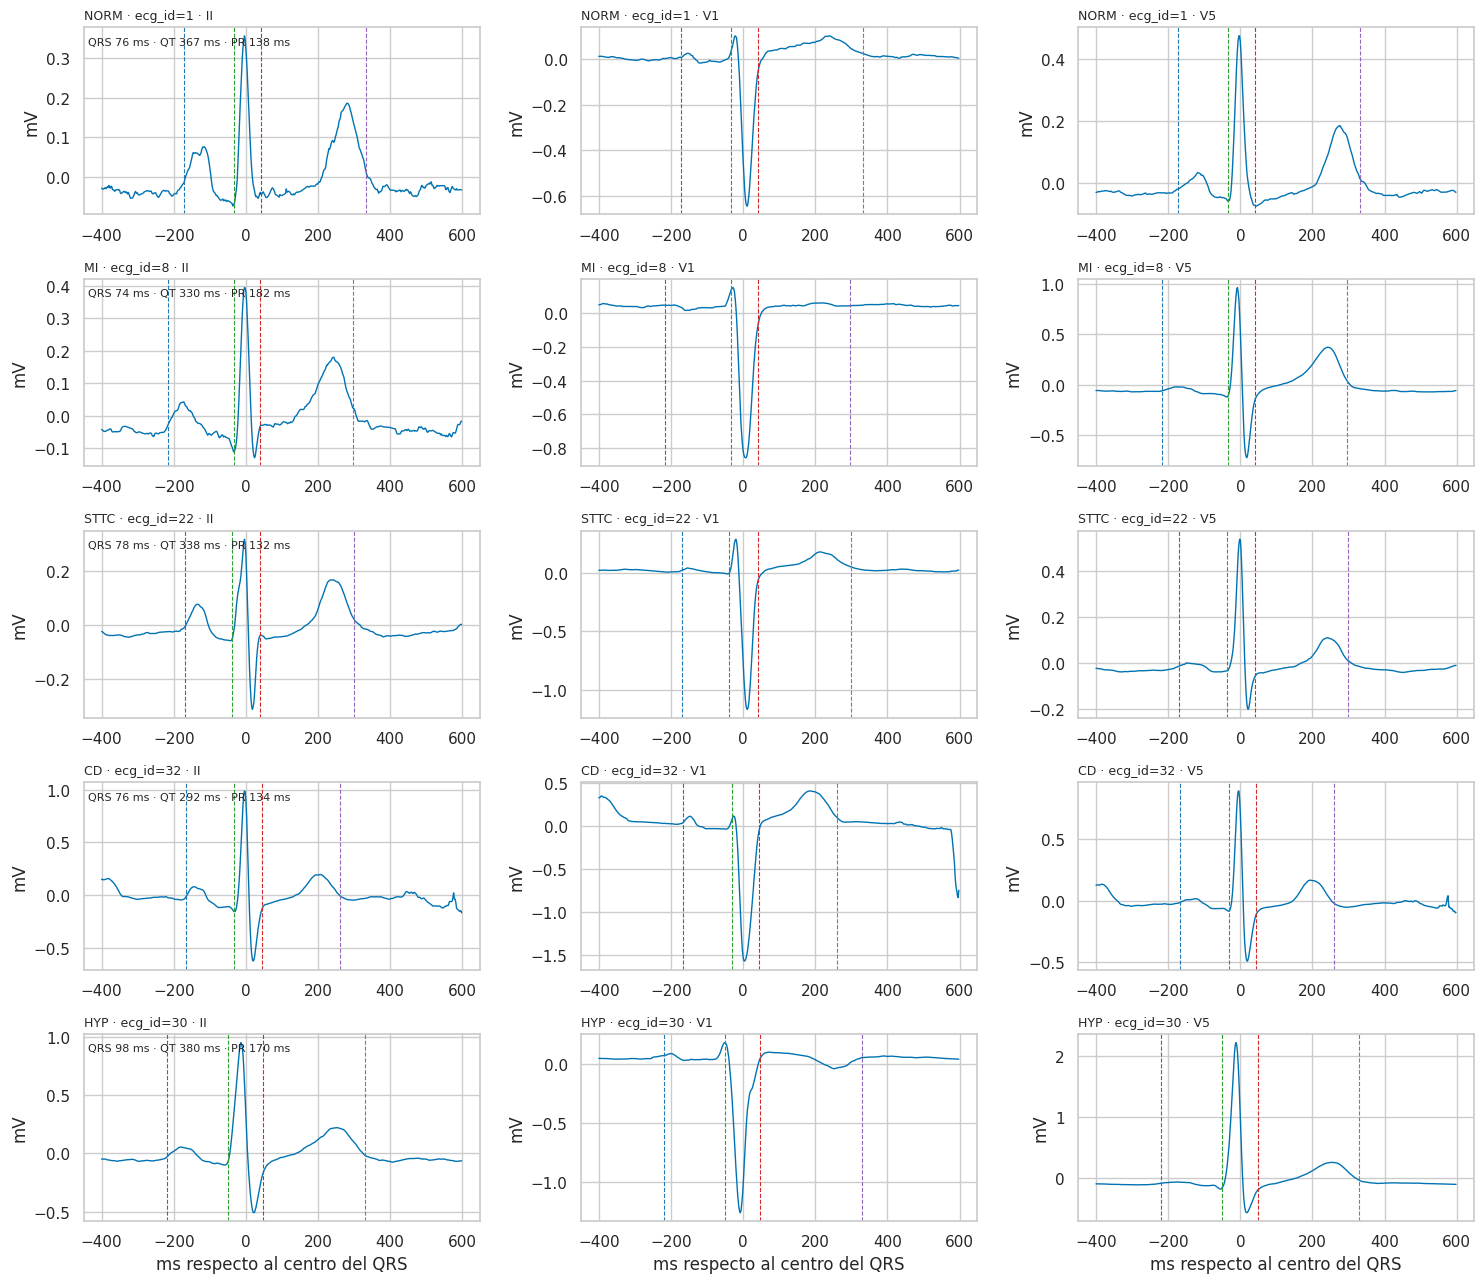

In [ ]:
examples = []
for sc in SUPERCLASSES:
    pool = [i for i in ids if meta.at[i, "superclasses"] == [sc] and sig.at[i, "status"] == "ok"]
    if pool:
        examples.append((sc, pool[0]))
fig, axes = plt.subplots(len(examples), 3, figsize=(15, 2.6 * len(examples)), squeeze=False)
for row, (sc, ecg_id) in enumerate(examples):
    feats, tpl = EF.median_beat(ecg_id, meta.at[ecg_id, "filename_hr"], str(DATA_DIR))
    t = (np.arange(len(tpl)) - EF.PRE) / EF.FS * 1000
    for col, lead in enumerate(["II", "V1", "V5"]):
        ax = axes[row, col]
        ax.plot(t, tpl[:, EF.L[lead]], lw=1)
        for key, color in [("fid_pon", "tab:blue"), ("fid_on", "tab:green"), ("fid_off", "tab:red"), ("fid_tend", "tab:purple")]:
            if pd.notna(feats.get(key, np.nan)):
                ax.axvline((feats[key] - EF.PRE) / EF.FS * 1000, color=color, lw=.8, ls="--")
        ax.set_title(f"{sc} · ecg_id={ecg_id} · {lead}", fontsize=9, loc="left")
        ax.set_ylabel("mV")
    axes[row, 0].text(0.01, 0.95, f"QRS {feats.get('qrs_ms', np.nan):.0f} ms · QT {feats.get('qt_ms', np.nan):.0f} ms · "
                      f"PR {feats.get('pr_ms', np.nan):.0f} ms", transform=axes[row, 0].transAxes, fontsize=8, va="top")
for ax in axes[-1]:
    ax.set_xlabel("ms respecto al centro del QRS")
plt.tight_layout(); plt.show()

**Lectura.** Las marcas caen donde las pondría un lector de ECG: el inicio de P al comienzo de la onda P, el inicio
del QRS antes de la q, el punto J al regresar la S y el fin de T cuando la T vuelve a la línea base. En el ejemplo
de HYP (ecg_id 30) el QRS mide 98 ms, más que en los otros casos, y su voltaje en V5 supera 2 mV, como corresponde
a una hipertrofia.

**Calibración.** En una primera ejecución, el umbral del 20% de la velocidad espacial recortaba la q inicial y
el final de la S, y daba una mediana de QRS de 62 ms, por debajo del rango normal de 80–100 ms. El umbral se
recalibró al 10% con un registro real de 12 derivaciones de la base PTB (s0010_re, tres ventanas de 10 s con
resultados idénticos). Con esa corrección, la mediana pasó a 76 ms y el grupo con QRS ≥120 ms creció de 508 a
913 ECG en entrenamiento, con 98% de CD.

**Limitación.** Los valores absolutos siguen siendo algo menores que los de los algoritmos comerciales: la mediana
de QTc de Bazett es 393 ms, y el método de la tangente tiende a adelantar el fin de T. Por eso las medidas se usan
como descriptores relativos entre ECG y no como mediciones clínicas.

### 1.5 Características combinadas con metadatos y diccionario

- **Índice de Cornell normalizado por sexo.** El criterio de Cornell usa umbrales distintos en hombres
  (2.8 mV) y mujeres (2.0 mV). Dividir el índice entre el umbral correspondiente crea una interacción
  clínicamente fundada: valores >1 cumplen el criterio de hipertrofia en ambos sexos con la misma escala.
- **Eje como seno y coseno.** El eje es un ángulo circular: −179° y +179° son casi iguales, pero como número
  son extremos opuestos. Representarlo con `cos` y `sin` conserva la cercanía angular. El ángulo crudo se
  usa solo para la categoría de la sección 2.
- **Edad.** Se crea `age_cens90`: la edad exacta, y 90 (cota inferior conocida) para los 90+. Es más honesto que
  imputar la mediana (61), como hacía la vista del EDA. En la sección 2 también se discretiza; la selección
  decidirá cuál conservar.

In [ ]:
sex_female = meta.loc[ids, "sex"].eq(1)                     # PTB-XL: 0 = hombre, 1 = mujer
feat = sig.copy()
feat["cornell_ratio"] = feat.cornell / np.where(sex_female, 2.0, 2.8)
feat["axis_cos"] = np.cos(np.radians(feat.qrs_axis))
feat["axis_sin"] = np.sin(np.radians(feat.qrs_axis))
feat["age_cens90"] = meta.loc[ids, "age_numeric"].where(~meta.loc[ids, "age_90plus"], 90.0)
feat["sex_female"] = sex_female.astype(int)

# Exclusiones heredadas del EDA
eligible = feat.index[feat.status.ne("lectura_fallida") & feat.constant_leads.fillna(1).eq(0)]
supervised = eligible[Y_all.loc[eligible].sum(axis=1).gt(0)]
funnel = pd.DataFrame({"etapa": ["metadatos procesados", "señales elegibles (sin canal constante)", "vista supervisada"],
                       "ECG": [len(feat), len(eligible), len(supervised)]})
if MODE == "full":
    funnel["ECG_en_Avance1.8"] = [21799, 21798, 21387]
display(funnel)

feature_dictionary = pd.DataFrame([
    ("hr", "Ritmo", "continua", "FC a partir de la mediana de RR", "CD, STTC"),
    ("rr_cv", "Ritmo", "continua", "Irregularidad de RR normalizada por la FC (sustituye a rr_std)", "CD, STTC"),
    ("pr_ms", "Intervalos", "continua", "PR largo: bloqueo AV", "CD"),
    ("qrs_ms", "Intervalos", "continua", "QRS ≥120 ms: bloqueo de rama", "CD"),
    ("qt_ms", "Intervalos", "continua", "Repolarización prolongada", "STTC"),
    ("qtc_bazett", "Intervalos", "continua", "QT corregido por FC (Bazett)", "STTC"),
    ("qtc_fridericia", "Intervalos", "continua", "QT corregido por FC (Fridericia, mejor a FC altas)", "STTC"),
    ("axis_cos / axis_sin", "Eje", "continua", "Eje del QRS en codificación circular", "CD, HYP"),
    ("sokolow_lyon", "Voltaje", "continua", "S V1 + R V5/V6: hipertrofia izquierda", "HYP"),
    ("cornell", "Voltaje", "continua", "R aVL + S V3: hipertrofia izquierda", "HYP"),
    ("cornell_ratio", "Voltaje", "continua", "Cornell / umbral por sexo (interacción)", "HYP"),
    ("r_v1", "Voltaje", "continua", "R alta en V1: hipertrofia derecha", "HYP"),
    ("p_amp_II", "Voltaje", "continua", "Amplitud de P: crecimiento auricular (incluido en HYP)", "HYP"),
    ("st_elev_* / st_dep_*", "ST", "continua", "Máxima elevación/depresión del ST por territorio", "MI, STTC"),
    ("t_inv_count", "Onda T", "conteo", "Derivaciones con T invertida (sin aVR, III, V1)", "STTC, MI"),
    ("q_path_count", "Onda Q / R", "conteo", "Derivaciones con Q patológica", "MI"),
    ("r_prog_slope", "Onda Q / R", "continua", "Pendiente de R de V1 a V4: progresión de R", "MI"),
    ("st_<derivación> (12)", "Bloque ST", "continua", "ST en J+60 ms por derivación → PCA/FA (sección 5)", "MI, STTC"),
    ("t_<derivación> (12)", "Bloque T", "continua", "Amplitud de T por derivación → PCA/FA (sección 5)", "STTC, MI"),
    ("amp_II, max_abs, signal_std", "Global (EDA)", "continua", "Amplitud global heredada del EDA", "HYP"),
    ("baseline_fraction, high_frequency_fraction", "Calidad (EDA)", "continua", "Potencia <0.7 Hz y >40 Hz: ruido", "covariable de calidad"),
    ("age_cens90", "Demografía", "continua", "Edad con 90+ en la cota inferior", "todas"),
    ("sex_female", "Demografía", "binaria", "Sexo", "todas"),
], columns=["caracteristica", "familia", "tipo", "fundamento", "superclase_relacionada"])
display(feature_dictionary)
feature_dictionary.to_csv(OUT / "diccionario_caracteristicas.csv", index=False)

,etapa,ECG,ECG_en_Avance1.8
0,metadatos procesados,21799,21799
1,señales elegibles (sin canal constante),21798,21798
2,vista supervisada,21387,21387


,caracteristica,familia,tipo,fundamento,superclase_relacionada
0,hr,Ritmo,continua,FC a partir de la mediana de RR,"CD, STTC"
1,rr_cv,Ritmo,continua,Irregularidad de RR normalizada por la FC (sus...,"CD, STTC"
2,pr_ms,Intervalos,continua,PR largo: bloqueo AV,CD
3,qrs_ms,Intervalos,continua,QRS ≥120 ms: bloqueo de rama,CD
4,qt_ms,Intervalos,continua,Repolarización prolongada,STTC
5,qtc_bazett,Intervalos,continua,QT corregido por FC (Bazett),STTC
6,qtc_fridericia,Intervalos,continua,"QT corregido por FC (Fridericia, mejor a FC al...",STTC
7,axis_cos / axis_sin,Eje,continua,Eje del QRS en codificación circular,"CD, HYP"
8,sokolow_lyon,Voltaje,continua,S V1 + R V5/V6: hipertrofia izquierda,HYP
9,cornell,Voltaje,continua,R aVL + S V3: hipertrofia izquierda,HYP


## 2. Discretización y codificación

### 2.1 Discretización con umbrales clínicos

Solo se discretiza cuando el corte tiene **significado propio**, nunca por cuantiles arbitrarios:

| Variable | Grupos | Justificación |
|---|---|---|
| Edad | 0–17, 18–29, 30–44, 45–59, 60–74, 75–89, 90+ | Resuelve la censura: "90+" es una categoría válida y no un número inventado. Son los mismos grupos del EDA. |
| FC | <60 bradicardia, 60–100 normal, >100 taquicardia | Umbrales clínicos estándar. |
| QRS | <110 normal, 110–119 bloqueo incompleto, ≥120 bloqueo completo | Criterio clínico de bloqueo de rama. |
| Eje | normal (−30° a 90°), izquierda (−90° a −30°), derecha (90° a 180°), extrema | Categorías clínicas del eje frontal. |

### 2.2 Codificación

- **Ordinal** para edad, FC y QRS: los grupos tienen un orden natural, así que un solo entero conserva esa
  información con una columna.
- **One-hot** para el eje: es circular y "extrema" queda entre izquierda y derecha, así que un entero
  impondría un orden falso. Se usa "normal" como categoría de referencia (se omite su columna) para evitar
  colinealidad perfecta en modelos lineales. Un eje no determinado queda con ceros y su indicador de faltante.
- **Binaria** para sexo: dos niveles, así que one-hot sería redundante.

In [ ]:
def ordinal(values, bins, labels):
    out = pd.cut(values, bins=bins, labels=False, right=False)
    return out.astype("float")

feat["age_band_ord"] = ordinal(meta.loc[ids, "age_numeric"], [0, 18, 30, 45, 60, 75, 90], None)
feat.loc[meta.loc[ids, "age_90plus"], "age_band_ord"] = 6.0
feat["hr_cat_ord"] = ordinal(feat.hr, [0, 60, 100.0001, np.inf], None)
feat["qrs_cat_ord"] = ordinal(feat.qrs_ms, [0, 110, 120, np.inf], None)

axis = feat.qrs_axis
axis_cat = pd.Series(np.select([axis.between(-30, 90), axis.ge(-90) & axis.lt(-30), axis.gt(90)],
                               ["normal", "izquierda", "derecha"], default="extrema"), index=feat.index)
axis_cat[axis.isna()] = "no_determinado"
feat["axis_cat"] = axis_cat
for cat in ["izquierda", "derecha", "extrema"]:
    feat[f"axis_{cat}"] = axis_cat.eq(cat).astype(int)

ORD = ["age_band_ord", "hr_cat_ord", "qrs_cat_ord"]
labels = {"age_band_ord": ["0–17", "18–29", "30–44", "45–59", "60–74", "75–89", "90+"],
          "hr_cat_ord": ["<60", "60–100", ">100"], "qrs_cat_ord": ["<110", "110–119", "≥120"]}

# Evidencia de que los cortes separan clases (solo entrenamiento de la vista supervisada)
tr = supervised[meta.loc[supervised, "split"].eq("train")]
for col in ORD + ["axis_cat"]:
    tab = Y_all.loc[tr].groupby(feat.loc[tr, col]).mean().mul(100).round(1)
    tab.insert(0, "ECG", feat.loc[tr, col].value_counts())
    if col in labels:
        tab.index = [labels[col][int(i)] for i in tab.index]
    display(tab.rename_axis(f"{col}: prevalencia % por grupo (train)"))

,ECG,NORM,MI,STTC,CD,HYP
age_band_ord: prevalencia % por grupo (train),,,,,,
0–17,111,84.7,0.9,5.4,15.3,2.7
18–29,979,86.3,2.9,6.1,10.2,3.2
30–44,2045,72.7,9.9,10.0,11.4,6.7
45–59,4625,51.2,23.5,20.1,17.6,9.6
60–74,5872,33.8,31.9,29.1,26.5,15.2
75–89,3239,24.2,34.0,36.2,33.7,17.7
90+,212,14.2,41.0,48.6,46.7,19.8


,ECG,NORM,MI,STTC,CD,HYP
hr_cat_ord: prevalencia % por grupo (train),,,,,,
<60,3149,51.9,23.5,18.8,19.9,10.3
60–100,12716,45.2,25.2,23.8,22.8,12.3
>100,1218,17.6,35.8,46.5,31.6,18.6


,ECG,NORM,MI,STTC,CD,HYP
qrs_cat_ord: prevalencia % por grupo (train),,,,,,
<110,15858,47.9,24.5,25.3,17.3,11.9
110–119,302,1.7,53.3,28.5,88.4,22.5
≥120,913,0.2,35.8,9.6,98.0,18.3


,ECG,NORM,MI,STTC,CD,HYP
axis_cat: prevalencia % por grupo (train),,,,,,
derecha,500,22.2,38.0,17.8,60.8,16.4
extrema,164,1.2,64.6,7.3,85.4,14.0
izquierda,1884,4.7,51.6,23.1,76.2,12.2
no_determinado,10,0.0,10.0,10.0,90.0,30.0
normal,14525,50.9,21.4,25.1,13.9,12.3


**Lectura.** Las tablas muestran que cada corte separa grupos con prevalencias muy distintas, lo que justifica
discretizar con umbrales clínicos:

- **Edad:** NORM cae de forma monótona, de 86.3% (18–29 años) a 14.2% (90+), mientras MI, STTC y CD aumentan. La
  relación monótona respalda la codificación **ordinal**. El grupo 90+ (212 ECG) conserva su propio perfil, con
  48.6% de STTC, en lugar de diluirse con la mediana de 61 años como en la vista del EDA.
- **FC:** en taquicardia (>100 lpm) NORM baja a 17.6% y STTC sube a 46.5%, frente a 23.8% con FC normal.
- **QRS:** con ≥120 ms, el 98.0% tiene CD y solo el 0.2% es NORM. El grupo intermedio de 110–119 ms también es
  casi exclusivamente CD (88.4%), así que el corte de bloqueo incompleto separa un grupo con significado propio.
- **Eje:** la desviación izquierda tiene 76.2% de CD y 4.7% de NORM, y la extrema 85.4% de CD y 64.6% de MI. El
  patrón no es monótono entre categorías, porque derecha e izquierda no son "más" o "menos" de algo. Eso respalda
  la codificación **one-hot** en lugar de la ordinal. Solo 10 ECG quedaron con eje no determinado.

## 3. Imputación, transformación y escalamiento

Desde aquí se trabaja con la vista supervisada. Todos los parámetros (medianas, límites, λ de Yeo–Johnson,
medias y desviaciones) se **ajustan solo con entrenamiento** y se aplican sin reajuste a validación y prueba.

### 3.1 Imputación con indicador

- Las continuas se imputan con la **mediana** de entrenamiento, que es robusta a la asimetría, y las ordinales
  con la **moda**.
- Para cada variable se crea un indicador `_missing`. La sección 1.3 mostró si el faltante depende de la
  superclase; si depende, el indicador conserva esa información.
- Los indicadores de variables sin faltantes saldrán constantes y los elimina el filtro de varianza
  (sección 4). Así el filtro actúa sobre el mismo problema que dejó la vista del EDA.

In [ ]:
CONT = ["age_cens90", "hr", "rr_cv", "pr_ms", "qrs_ms", "qt_ms", "qtc_bazett", "qtc_fridericia",
        "axis_cos", "axis_sin", "sokolow_lyon", "cornell", "cornell_ratio", "r_v1", "p_amp_II",
        "q_path_count", "r_prog_slope", "t_inv_count",
        "st_elev_anterior", "st_dep_anterior", "st_elev_lateral", "st_dep_lateral", "st_elev_inferior", "st_dep_inferior",
        "amp_II", "max_abs", "signal_std", "baseline_fraction", "high_frequency_fraction"]
BIN = ["sex_female", "axis_izquierda", "axis_derecha", "axis_extrema"]
BLOCKS = {"ST": [f"st_{l}" for l in LEADS], "T": [f"t_{l}" for l in LEADS]}
family = {"age_cens90": "Demografía", "sex_female": "Demografía", "age_band_ord": "Demografía",
          "hr": "Ritmo", "rr_cv": "Ritmo", "hr_cat_ord": "Ritmo",
          "pr_ms": "Intervalos", "qrs_ms": "Intervalos", "qt_ms": "Intervalos", "qtc_bazett": "Intervalos",
          "qtc_fridericia": "Intervalos", "qrs_cat_ord": "Intervalos",
          "axis_cos": "Eje", "axis_sin": "Eje", "axis_izquierda": "Eje", "axis_derecha": "Eje", "axis_extrema": "Eje",
          "sokolow_lyon": "Voltaje", "cornell": "Voltaje", "cornell_ratio": "Voltaje", "r_v1": "Voltaje", "p_amp_II": "Voltaje",
          "q_path_count": "Onda Q / R", "r_prog_slope": "Onda Q / R", "t_inv_count": "Onda T",
          "amp_II": "Global (EDA)", "max_abs": "Global (EDA)", "signal_std": "Global (EDA)",
          "baseline_fraction": "Calidad (EDA)", "high_frequency_fraction": "Calidad (EDA)"}
family.update({c: "ST" for c in CONT if c.startswith("st_")})

work = feat.loc[supervised].copy()
Y = Y_all.loc[supervised]
split = meta.loc[supervised, "split"]
train = split.eq("train")
print("ECG por partición:", split.value_counts().to_dict())

MISS = []
for c in CONT + ORD:
    work[f"{c}_missing"] = work[c].isna().astype(int)
    MISS.append(f"{c}_missing")
medians = work.loc[train, CONT].median()
modes = work.loc[train, ORD].mode().iloc[0]
X_imp = work[CONT + ORD + BIN + MISS].copy()
X_imp[CONT] = X_imp[CONT].fillna(medians)
X_imp[ORD] = X_imp[ORD].fillna(modes)
assert X_imp.notna().all().all()
display(pd.DataFrame({"faltantes_%": work[CONT + ORD].isna().mean() * 100,
                      "valor_imputado_train": pd.concat([medians, modes])}).round(3)
        .sort_values("faltantes_%", ascending=False).head(15))

ECG por partición: {'train': 17083, 'test': 2158, 'validation': 2146}


,faltantes_%,valor_imputado_train
pr_ms,17.034,158.000
p_amp_II,17.006,0.101
qtc_bazett,0.337,392.682
qtc_fridericia,0.337,380.407
qt_ms,0.337,359.521
t_inv_count,0.098,0.000
axis_cos,0.047,0.859
qrs_ms,0.047,76.000
cornell,0.047,1.295
cornell_ratio,0.047,0.543


### 3.2 Recorte de extremos (winsorización)

El EDA conservó registros con artefactos, como picos >10 mV o un residual de 32 mV en el ECG 10565.
Eliminarlos solo por su magnitud no se justificaba, pero tampoco deben dominar la media y la desviación del
escalamiento. Se recortan las continuas a los percentiles 0.5 y 99.5 de entrenamiento. El registro se conserva
y solo se limita la influencia del valor extremo.

In [ ]:
lo, hi = X_imp.loc[train, CONT].quantile(.005), X_imp.loc[train, CONT].quantile(.995)
X_w = X_imp.copy()
X_w[CONT] = X_imp[CONT].clip(lo, hi, axis=1)
clipped = (X_imp[CONT] != X_w[CONT]).loc[train].mean().mul(100)
display(pd.DataFrame({"p0.5": lo, "p99.5": hi, "%_recortado_train": clipped}).round(3))

,p0.5,p99.5,%_recortado_train
age_cens90,17.000,90.000,0.486
hr,44.079,147.059,1.001
rr_cv,0.003,0.367,1.007
pr_ms,74.000,266.000,0.913
qrs_ms,58.000,166.000,0.942
qt_ms,261.100,513.225,1.007
qtc_bazett,318.823,572.074,1.007
qtc_fridericia,310.467,550.640,1.007
axis_cos,-0.861,1.000,1.007
axis_sin,-0.990,1.000,1.007


### 3.3 Transformación de variables asimétricas

**Criterio:** solo se transforma si |asimetría| > 1 en entrenamiento, el umbral convencional de asimetría
fuerte. La rúbrica pide transformar "si es necesario", así que el criterio se aplica variable por variable.

**Por qué Yeo–Johnson:** varias variables toman valores negativos o cero (desviación del ST, coseno y seno del
eje, pendiente de R, conteos). El logaritmo y Box–Cox exigen valores positivos, mientras que Yeo–Johnson acepta
cualquier signo y estima λ por máxima verosimilitud, eligiendo la potencia que más acerca la variable a una
normal. Eso favorece las pruebas ANOVA de la sección 4 y a los modelos lineales. Antes de transformar, cada
variable se centra y escala con parámetros de entrenamiento: Yeo–Johnson no es invariante a la escala y, en
variables de magnitud grande como el QTc (cientos de ms), la λ estimada se vuelve extrema y colapsa la variable.

,asimetria_antes,transformada,lambda,asimetria_despues
st_elev_anterior,3.013,True,0.042,-0.109
q_path_count,2.871,True,-2.443,1.320
r_v1,2.743,True,-0.259,0.109
t_inv_count,2.605,True,-2.615,1.384
st_dep_lateral,-2.473,True,2.069,0.062
high_frequency_fraction,2.452,True,-0.081,0.077
qrs_ms,2.337,True,-0.142,-0.014
baseline_fraction,2.251,True,-0.663,0.382
rr_cv,2.231,True,-1.178,0.533
axis_cos,-2.078,True,2.429,-0.329


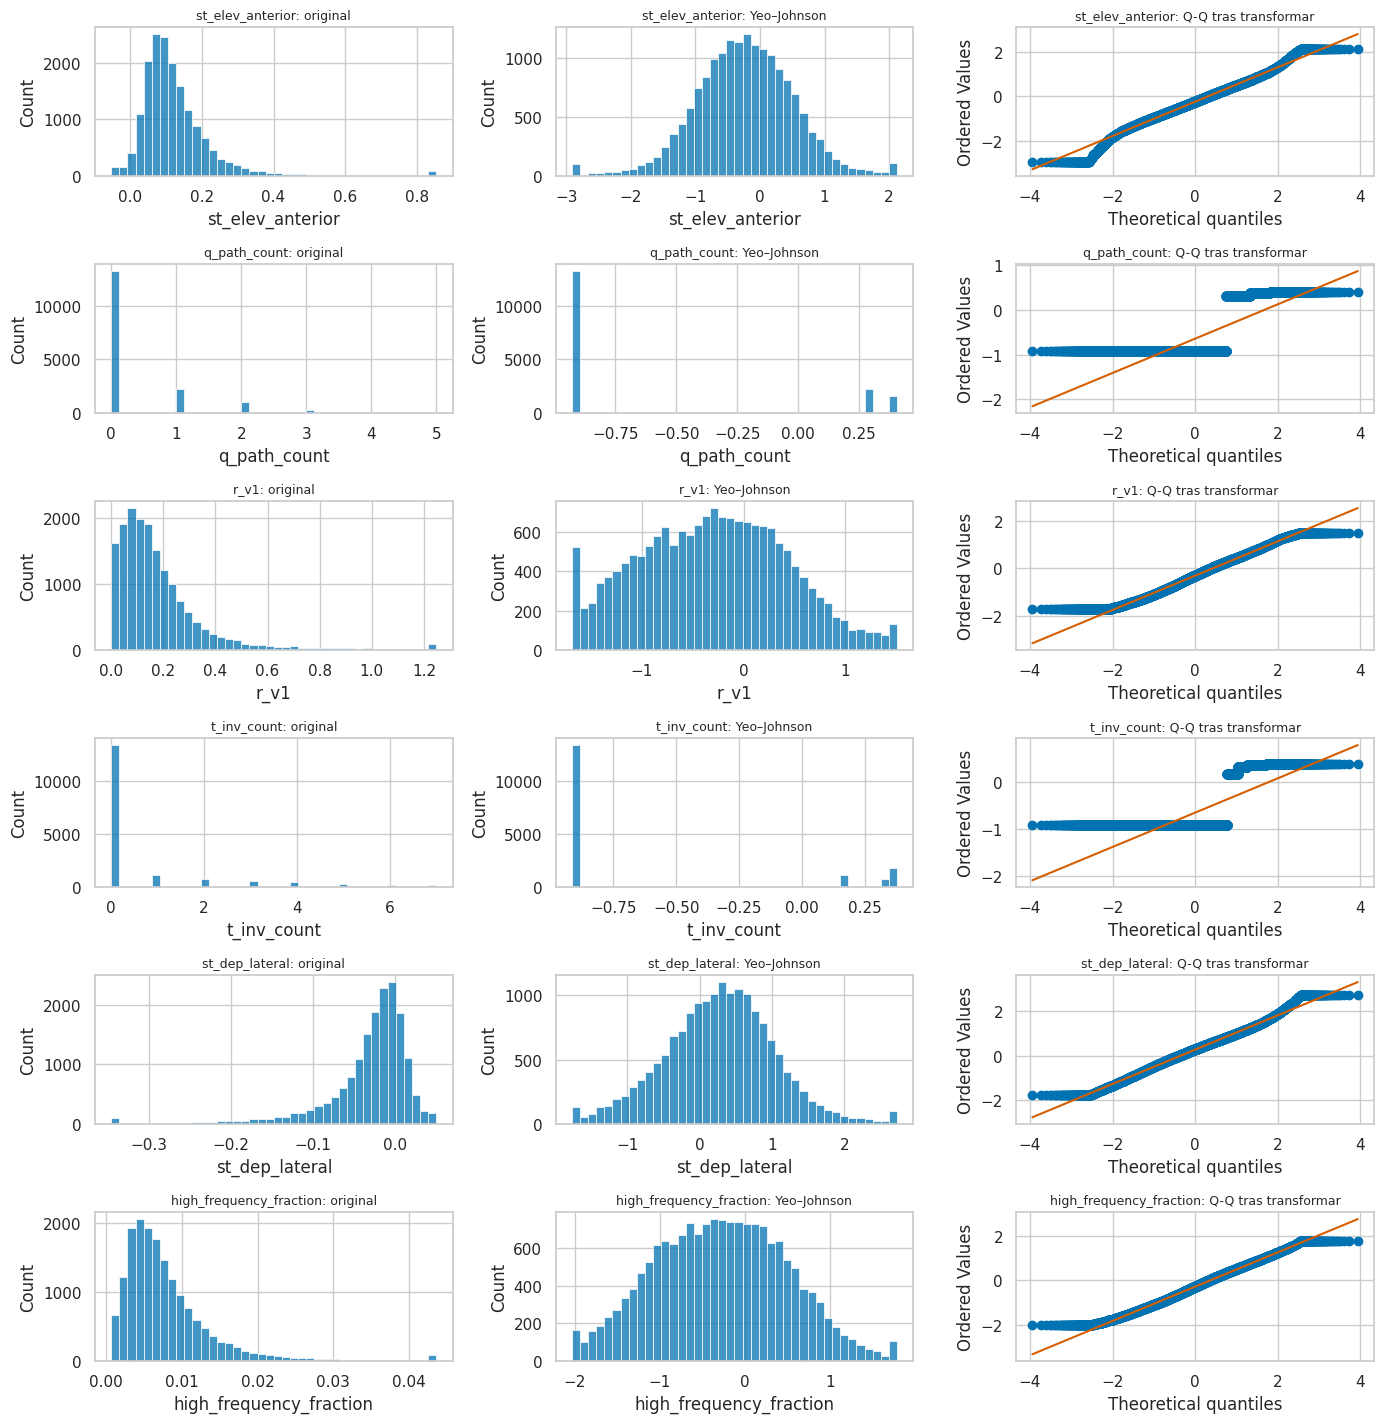

In [ ]:
skew_before = X_w.loc[train, CONT].skew()
to_transform = skew_before.index[skew_before.abs().gt(1)].tolist()
# Yeo–Johnson no es invariante a la escala: en variables de cientos (QTc en ms) la λ estimada se vuelve
# extrema y la variable colapsa numéricamente. Se centra y escala primero (parámetros de train).
pre_yj = StandardScaler().fit(X_w.loc[train, to_transform])
yj = PowerTransformer(method="yeo-johnson", standardize=False).fit(pre_yj.transform(X_w.loc[train, to_transform]))
X_t = X_w.copy()
X_t[to_transform] = yj.transform(pre_yj.transform(X_w[to_transform]))
skew_table = pd.DataFrame({"asimetria_antes": skew_before,
                           "transformada": pd.Series(skew_before.index.isin(to_transform), index=skew_before.index),
                           "lambda": pd.Series(yj.lambdas_, index=to_transform),
                           "asimetria_despues": X_t.loc[train, CONT].skew()}).round(3)
display(skew_table.sort_values("asimetria_antes", key=abs, ascending=False))

show = skew_before[to_transform].abs().sort_values(ascending=False).index[:6]
fig, axes = plt.subplots(len(show), 3, figsize=(14, 2.4 * len(show)), squeeze=False)
for i, c in enumerate(show):
    sns.histplot(X_w.loc[train, c], bins=40, ax=axes[i, 0]); axes[i, 0].set_title(f"{c}: original", fontsize=9)
    sns.histplot(X_t.loc[train, c], bins=40, ax=axes[i, 1]); axes[i, 1].set_title(f"{c}: Yeo–Johnson", fontsize=9)
    stats.probplot(X_t.loc[train, c], dist="norm", plot=axes[i, 2]); axes[i, 2].set_title(f"{c}: Q-Q tras transformar", fontsize=9)
plt.tight_layout(); plt.show()

**Lectura.** 20 de las 29 variables continuas tenían |asimetría| > 1 y se transformaron. Para la mayoría, la
asimetría quedó cerca de cero: `st_elev_anterior` de 3.01 a −0.11, `qrs_ms` de 2.34 a −0.01, `r_v1` de 2.74 a 0.11
y `st_dep_lateral` de −2.47 a 0.06. Las gráficas Q-Q muestran puntos alineados con la recta normal salvo en las
colas extremas.

Las λ tienen lectura directa. Cuando λ < 1 (por ejemplo, −0.14 en `qrs_ms`, cercano a un logaritmo), la
transformación comprime la cola derecha de las variables con asimetría positiva. Cuando λ > 1 (2.07 en
`st_dep_lateral` y 2.43 en `axis_cos`), estira la cola izquierda de las variables con asimetría negativa.

**Excepción.** `q_path_count` y `t_inv_count` bajaron de 2.87 a 1.32 y de 2.61 a 1.38, pero no llegaron a la
simetría. Son conteos (0 a 9 derivaciones) donde la mayoría de los ECG vale 0, y ninguna transformación monótona
puede repartir una masa de valores idénticos. Se conservan transformadas: con miles de observaciones, ANOVA es
robusta a esta desviación de la normalidad.

### 3.4 Escalamiento

**Estandarización** (media 0, desviación 1) para continuas y ordinales. Se elige sobre min-max porque, después
de recortar extremos y transformar, las distribuciones son aproximadamente simétricas y la estandarización
iguala la dispersión sin depender de los dos valores más extremos de cada variable. Con esto todas las
variables entran con un **impacto equitativo** en métodos basados en gradiente, distancias o regularización.

Las binarias (sexo, eje one-hot, indicadores) **no se escalan**: ya están en {0, 1} y conservan una
interpretación directa como presencia o ausencia.

,min_antes,max_antes,std_antes,media_despues,std_despues
age_cens90,17.000,90.000,16.864,0.0,1.0
hr,44.079,147.059,16.774,-0.0,1.0
rr_cv,0.003,0.367,0.072,0.0,1.0
pr_ms,74.000,266.000,27.415,0.0,1.0
qrs_ms,58.000,166.000,18.163,0.0,1.0
qt_ms,261.100,513.225,38.442,-0.0,1.0
qtc_bazett,318.823,572.074,34.035,-0.0,1.0
qtc_fridericia,310.467,550.640,30.455,-0.0,1.0
axis_cos,-0.861,1.000,0.332,-0.0,1.0
axis_sin,-0.990,1.000,0.542,0.0,1.0


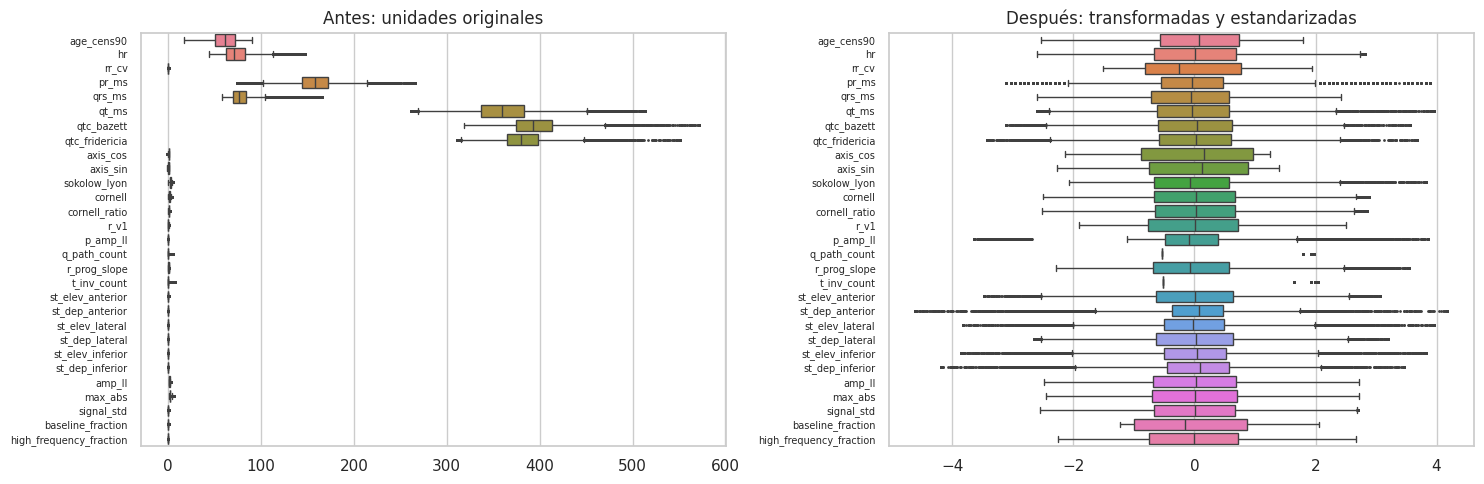

In [ ]:
SCALE = CONT + ORD
scaler = StandardScaler().fit(X_t.loc[train, SCALE])
X_s = X_t.copy()
X_s[SCALE] = scaler.transform(X_t[SCALE])
before_after = pd.DataFrame({"min_antes": X_w.loc[train, SCALE].min(), "max_antes": X_w.loc[train, SCALE].max(),
                             "std_antes": X_w.loc[train, SCALE].std(),
                             "media_despues": X_s.loc[train, SCALE].mean(), "std_despues": X_s.loc[train, SCALE].std()})
display(before_after.round(3))
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
sns.boxplot(data=X_w.loc[train, CONT], orient="h", ax=axes[0], fliersize=1); axes[0].set_title("Antes: unidades originales")
sns.boxplot(data=X_s.loc[train, CONT], orient="h", ax=axes[1], fliersize=1); axes[1].set_title("Después: transformadas y estandarizadas")
for ax in axes: ax.tick_params(axis="y", labelsize=7)
plt.tight_layout(); plt.show()

### 3.5 Evidencia: efecto del escalamiento en la convergencia

Una regresión logística ajusta sus pesos por pasos y converge cuando los ajustes dejan de mejorar el error.
Con variables en escalas muy distintas (QT en cientos de milisegundos, ST en décimas de milivoltio), la
superficie de error queda alargada y el optimizador avanza en zigzag. Se entrena la misma regresión logística
por superclase con las variables **sin escalar** y **escaladas**, y se mide cuántas iteraciones necesita.

- `saga` (gradiente estocástico) es sensible a la escala, como las redes neuronales.
- `lbfgs` (cuasi-Newton) es menos sensible y sirve de contraste.

**No se reporta ninguna métrica de desempeño:** el modelo es solo un instrumento para medir convergencia.

In [ ]:
def fit_stats(X, solver, max_iter):
    rows = []
    for sc in SUPERCLASSES:
        model = LogisticRegression(solver=solver, max_iter=max_iter, tol=1e-4)
        with warnings.catch_warnings(record=True) as w:
            warnings.simplefilter("always", ConvergenceWarning)
            t0 = time.time()
            model.fit(X.loc[train], Y.loc[train, sc])
            elapsed = time.time() - t0
        rows.append({"superclase": sc, "iteraciones": int(model.n_iter_[0]),
                     "convergio": not any(issubclass(x.category, ConvergenceWarning) for x in w),
                     "segundos": elapsed})
    return pd.DataFrame(rows)

conv = []
for solver, max_iter in [("saga", 1000), ("lbfgs", 1000)]:
    for name, X in [("sin escalar", X_w), ("escaladas", X_s)]:
        conv.append(fit_stats(X, solver, max_iter).assign(solver=solver, variables=name))
convergence = pd.concat(conv)
display(convergence.pivot_table(index="superclase", columns=["solver", "variables"],
                                values=["iteraciones", "convergio", "segundos"], aggfunc="first").round(2))
convergence.to_csv(OUT / "convergencia_escalamiento.csv", index=False)

convergio                                   iteraciones                                    segundos                                  
solver         lbfgs                  saga                   lbfgs                  saga                 lbfgs                  saga            
variables  escaladas sin escalar escaladas sin escalar   escaladas sin escalar escaladas sin escalar escaladas sin escalar escaladas sin escalar
superclase                                                                                                                                      
CD              True       False      True       False          40        1000       268        1000      0.41        9.46      2.01        7.48
HYP             True       False      True       False          52        1000       262        1000      0.59        9.79      1.96        7.44
MI              True       False      True       False          55        1000       291        1000      0.62        9.81      2.16        7.37
NORM            True       False      True       False          72        1000       262        1000      0.76       10.54      1.95        7.47
STTC            True       False      True       False          47        1000       216        1000      0.38        9.94      1.61        7.46

**Lectura.** El efecto del escalamiento es contundente y se repite en las cinco superclases:

- Con **saga**, ninguna regresión convergió sin escalar dentro del límite de 1000 iteraciones. Con las variables
  escaladas, todas convergieron en 216 a 291 iteraciones, y el tiempo bajó de ~7.4 s a ~2 s por superclase.
- Con **lbfgs** pasó lo mismo: sin escalar agotó las 1000 iteraciones en todas las superclases; escaladas, convergió
  en 40 a 72 iteraciones y más de 10 veces más rápido (~10 s contra 0.4–0.8 s).

Que también falle lbfgs muestra la magnitud del problema: el QT (cientos de ms) y la desviación del ST (centésimas
de mV) difieren en cuatro órdenes de magnitud. Esto respalda el objetivo 2.4 con evidencia y no solo con teoría.

## 4. Selección de características por filtrado

Los métodos de filtrado evalúan cada variable con estadísticos, sin entrenar un modelo, por lo que son
rápidos y no dependen de un algoritmo concreto. Se aplican en cascada y cada paso decide con resultados
del anterior:

1. **Umbral de varianza:** elimina lo que no varía.
2. **Relevancia con las etiquetas:** ANOVA y chi-cuadrado por superclase.
3. **Redundancia entre predictores:** correlación de Spearman. Va al final porque, ante un par redundante,
   se conserva la variable con mayor relevancia según el paso 2, no una al azar.

Los bloques de ST y T por derivación no pasan por este filtro: su redundancia es estructural (derivaciones
vecinas miran el corazón desde ángulos parecidos) y se trata con extracción en la sección 5.

### 4.1 Umbral de varianza

Se evalúa **antes de estandarizar**, porque después todas las varianzas valen 1.

- **Continuas y ordinales:** se elimina solo la varianza cero. Su varianza depende de las unidades
  (ms contra mV), así que cualquier otro umbral sería arbitrario.
- **Binarias:** su varianza es p(1−p), con escala natural. Se eliminan las que tienen menos de 0.5% de
  casos en la clase minoritaria, porque con tan pocos casos las tablas de chi-cuadrado por superclase
  tendrían frecuencias esperadas muy bajas y la estimación sería inestable.

In [ ]:
var = X_w.loc[train].var()
p = X_w.loc[train, BIN + MISS].mean()
minority = np.minimum(p, 1 - p)
drop_var = var.index[var.eq(0)].tolist() + minority.index[minority.lt(0.005)].tolist()
drop_var = sorted(set(drop_var))
variance_table = pd.DataFrame({"varianza_train": var, "proporcion_minoritaria": minority}).loc[drop_var]
display(variance_table.round(5))
after_var = [c for c in CONT + ORD + BIN + MISS if c not in drop_var]
print(f"Candidatas: {len(CONT + ORD + BIN + MISS)} → tras umbral de varianza: {len(after_var)}")

,varianza_train,proporcion_minoritaria
age_band_ord_missing,0.00000,0.00000
age_cens90_missing,0.00000,0.00000
amp_II_missing,0.00000,0.00000
axis_cos_missing,0.00059,0.00059
axis_sin_missing,0.00059,0.00059
baseline_fraction_missing,0.00000,0.00000
cornell_missing,0.00059,0.00059
cornell_ratio_missing,0.00059,0.00059
high_frequency_fraction_missing,0.00000,0.00000
hr_cat_ord_missing,0.00000,0.00000


Candidatas: 68 → tras umbral de varianza: 38


**Lectura.** El umbral de varianza eliminó **30 de 68 candidatas**, y todas son indicadores de faltante:

- **10 constantes:** corresponden a variables sin ningún faltante en entrenamiento (FC, edad, amplitudes globales).
  Son exactamente el tipo de columna constante que dejó la vista tabular del EDA.
- **20 casi constantes:** indicadores con menos de 0.5% de casos, de 0.06% a 0.34%. Reflejan las fallas aisladas
  de delineación de la sección 1.3. Con tan pocos casos no pueden sostener una prueba por superclase ni aportar
  información estable.

Ninguna característica clínica se eliminó en este paso, y solo sobreviven los indicadores de la onda P, cuyo
faltante sí es frecuente (17%).

### 4.2 Relevancia con las etiquetas: ANOVA y chi-cuadrado

ANOVA y chi-cuadrado relacionan un predictor con **una** variable objetivo, así que se aplican una vez por
superclase (uno contra el resto):

- **ANOVA (F)** para las continuas, ya transformadas y escaladas: compara la media del predictor entre ECG
  con y sin la superclase. Yeo–Johnson acercó estas variables a la normalidad que supone la prueba.
- **Chi-cuadrado** para ordinales y binarias: compara la distribución de categorías entre ECG con y sin la
  superclase.

Tres decisiones metodológicas:

1. **Un ECG por paciente.** Las pruebas suponen observaciones independientes y el EDA mostró pacientes con
   varios ECG. Las pruebas usan el primer ECG de cada paciente en entrenamiento.
2. **Tamaño del efecto, no solo p-valor.** Con miles de ECG casi cualquier diferencia mínima sale
   "significativa". Se mide la proporción de variabilidad explicada: η² para ANOVA y V² de Cramér para
   chi-cuadrado. Ambas están en la misma escala, que en tablas 2×2 equivale a r².
3. **Corrección por comparaciones múltiples.** Se hacen (variables × 5) pruebas, así que los p-valores se
   corrigen con Benjamini–Hochberg (FDR).

**Criterio:** una variable es relevante si en **al menos una** superclase tiene q < 0.05 y un efecto
≥ 0.01, el umbral de efecto pequeño de Cohen (η² = 0.01; V = 0.10). Basta con una superclase porque
algunas variables son específicas: los índices de voltaje importan para HYP y casi nada para el resto.

ECG para pruebas (uno por paciente, train): 14,822


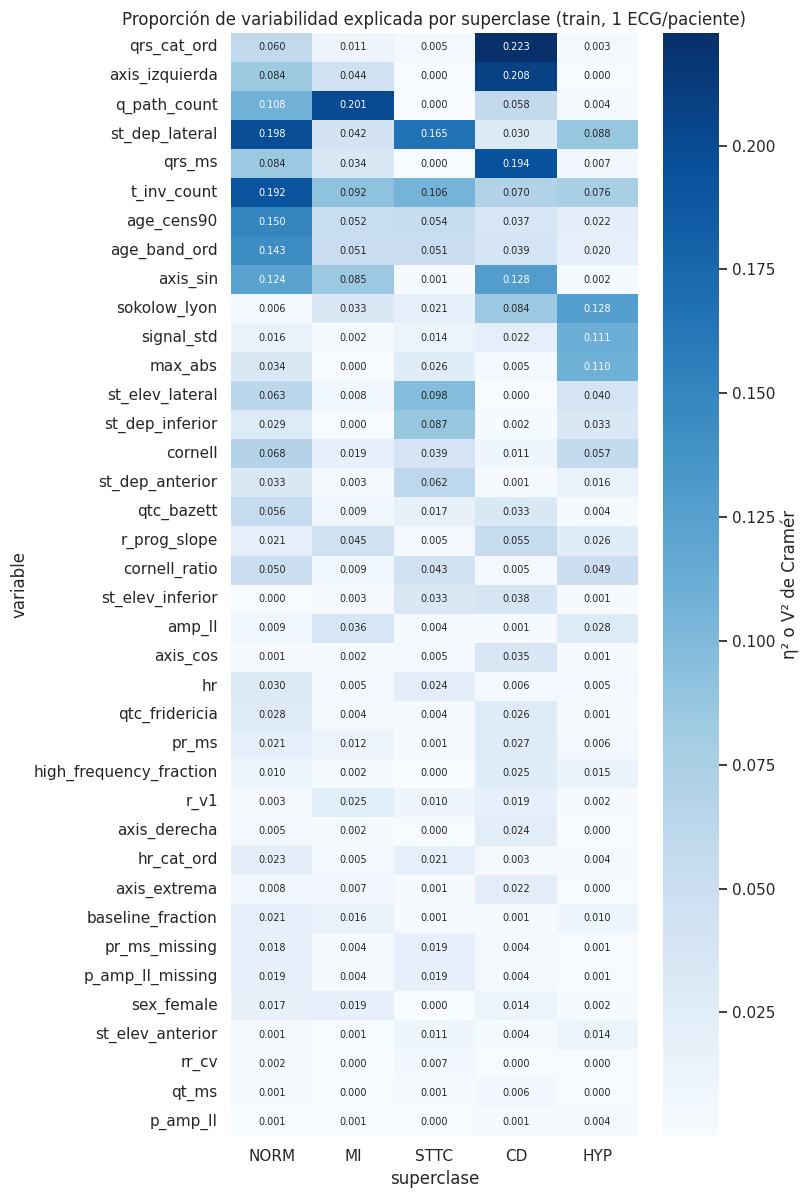

,efecto_max,superclase_max,relevante
variable,,,
qrs_cat_ord,0.2227,CD,True
axis_izquierda,0.2078,CD,True
q_path_count,0.2006,MI,True
st_dep_lateral,0.1976,NORM,True
qrs_ms,0.1943,CD,True
t_inv_count,0.1922,NORM,True
age_cens90,0.1505,NORM,True
age_band_ord,0.1428,NORM,True
axis_sin,0.1284,CD,True


Tras relevancia: 35 (eliminadas: ['rr_cv', 'qt_ms', 'p_amp_II'])


In [ ]:
first_ecg = meta.loc[supervised].loc[train].sort_values("recording_date").groupby("patient_id").head(1).index
rel = first_ecg
print(f"ECG para pruebas (uno por paciente, train): {len(rel):,}")

anova_cols = [c for c in after_var if c in CONT]
chi_cols = [c for c in after_var if c not in CONT]
records = []
for sc in SUPERCLASSES:
    y = Y.loc[rel, sc]
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")          # una variable constante en el subconjunto da F indefinida; se descarta abajo
        F, pv = f_classif(X_s.loc[rel, anova_cols], y)
    for c, f_, p_ in zip(anova_cols, F, pv):
        records.append({"variable": c, "superclase": sc, "prueba": "ANOVA", "estadistico": f_, "p": p_,
                        "efecto": f_ / (f_ + len(rel) - 2)})            # η² con 2 grupos
    for c in chi_cols:
        tab = pd.crosstab(X_s.loc[rel, c], y)
        if tab.shape[0] < 2:
            continue
        chi2, p_, _, _ = stats.chi2_contingency(tab, correction=False)
        records.append({"variable": c, "superclase": sc, "prueba": "chi-cuadrado", "estadistico": chi2, "p": p_,
                        "efecto": chi2 / tab.values.sum()})           # V² de Cramér (2 columnas)
tests = pd.DataFrame(records).dropna(subset=["p"])
tests["q_BH"] = stats.false_discovery_control(tests.p.clip(lower=1e-300), method="bh")
tests["relevante"] = tests.q_BH.lt(0.05) & tests.efecto.ge(0.01)
effect = tests.pivot(index="variable", columns="superclase", values="efecto").reindex(index=after_var, columns=SUPERCLASSES)
relevance = effect.max(axis=1).fillna(0).rename("efecto_max")
relevant = tests.groupby("variable").relevante.any().reindex(after_var, fill_value=False)   # sin prueba posible = no relevante
drop_rel = relevant.index[~relevant].tolist()

fig, ax = plt.subplots(figsize=(8, 0.28 * len(effect) + 1.5))
sns.heatmap(effect.loc[relevance.sort_values(ascending=False).index], annot=True, fmt=".3f", cmap="Blues",
            annot_kws={"size": 7}, ax=ax, cbar_kws={"label": "η² o V² de Cramér"})
ax.set_title("Proporción de variabilidad explicada por superclase (train, 1 ECG/paciente)")
plt.tight_layout(); plt.show()
display(pd.DataFrame({"efecto_max": relevance, "superclase_max": effect.fillna(0).idxmax(axis=1),
                      "relevante": relevant}).sort_values("efecto_max", ascending=False).round(4))
after_rel = [c for c in after_var if c not in drop_rel]
print(f"Tras relevancia: {len(after_rel)} (eliminadas: {drop_rel})")
tests.to_csv(OUT / "pruebas_relevancia.csv", index=False)

**Lectura.** Las pruebas usaron 14,822 ECG, uno por paciente. **35 de las 38 variables** resultaron relevantes
para al menos una superclase. Las más relevantes coinciden con la fisiología de cada clase:

| Superclase | Variables con mayor efecto (η² o V²) |
|---|---|
| CD | `qrs_cat_ord` (0.223), `axis_izquierda` (0.208), `qrs_ms` (0.194) |
| MI | `q_path_count` (0.201) |
| NORM | `st_dep_lateral` (0.198), `t_inv_count` (0.192), `age_cens90` (0.151) |
| HYP | `sokolow_lyon` (0.128), `signal_std` (0.111), `max_abs` (0.110) |
| STTC | `st_elev_lateral` (0.098), `st_dep_inferior` (0.087) |

**Comparación con el EDA.** La edad explica prácticamente la misma proporción de la variabilidad de NORM en ambos
análisis (η² = 0.151; en el EDA, Spearman = −0.389, es decir, 0.389² ≈ 0.151), lo que funciona como control de
consistencia. La diferencia está en las demás clases. En el EDA, las asociaciones más fuertes de MI y CD eran la
edad y la amplitud global (Spearman ≤ 0.22, menos de 0.05 de proporción de varianza). Ahora **cada una tiene
variables propias** con efectos de 0.19 a 0.22, unas cuatro veces mayores.

**Las tres eliminadas también dicen algo:**
- `qt_ms` es irrelevante (0.006), pero `qtc_bazett` sí lo es (0.056): la información está en el QT **corregido por
  frecuencia**, no en el QT crudo.
- `rr_cv` (0.007): 10 s, unos 12 latidos, son muy pocos para medir variabilidad del ritmo.
- `p_amp_II` (0.004): la amplitud de la P no distingue clases, pero su **ausencia** (`pr_ms_missing`, 0.019 en
  STTC) sí.

Por último, `qrs_cat_ord` (0.223) supera a la duración continua `qrs_ms` (0.194). El bloqueo de rama es un
fenómeno de umbral, y el corte clínico lo captura mejor que la escala continua.

### 4.3 Redundancia entre predictores: correlación

Dos variables casi idénticas aportan la misma información, duplican el almacenamiento y, en modelos lineales,
vuelven inestables los coeficientes (multicolinealidad). Se usa **Spearman** porque mide asociación monótona
y no exige linealidad. Para cada par con |ρ| > 0.9 se elimina la variable con **menor efecto máximo** de la
sección 4.2. El umbral de 0.9 marca casi duplicados: ρ² > 0.81, es decir, más del 80% de la variación de los
rangos es compartida.

,par,rho,efecto_a,efecto_b,se_elimina
0,pr_ms_missing ~ p_amp_II_missing,0.9990,0.0187,0.0187,p_amp_II_missing
1,age_cens90 ~ age_band_ord,0.9650,0.1505,0.1428,age_band_ord
2,cornell ~ cornell_ratio,0.9327,0.0682,0.0500,cornell_ratio


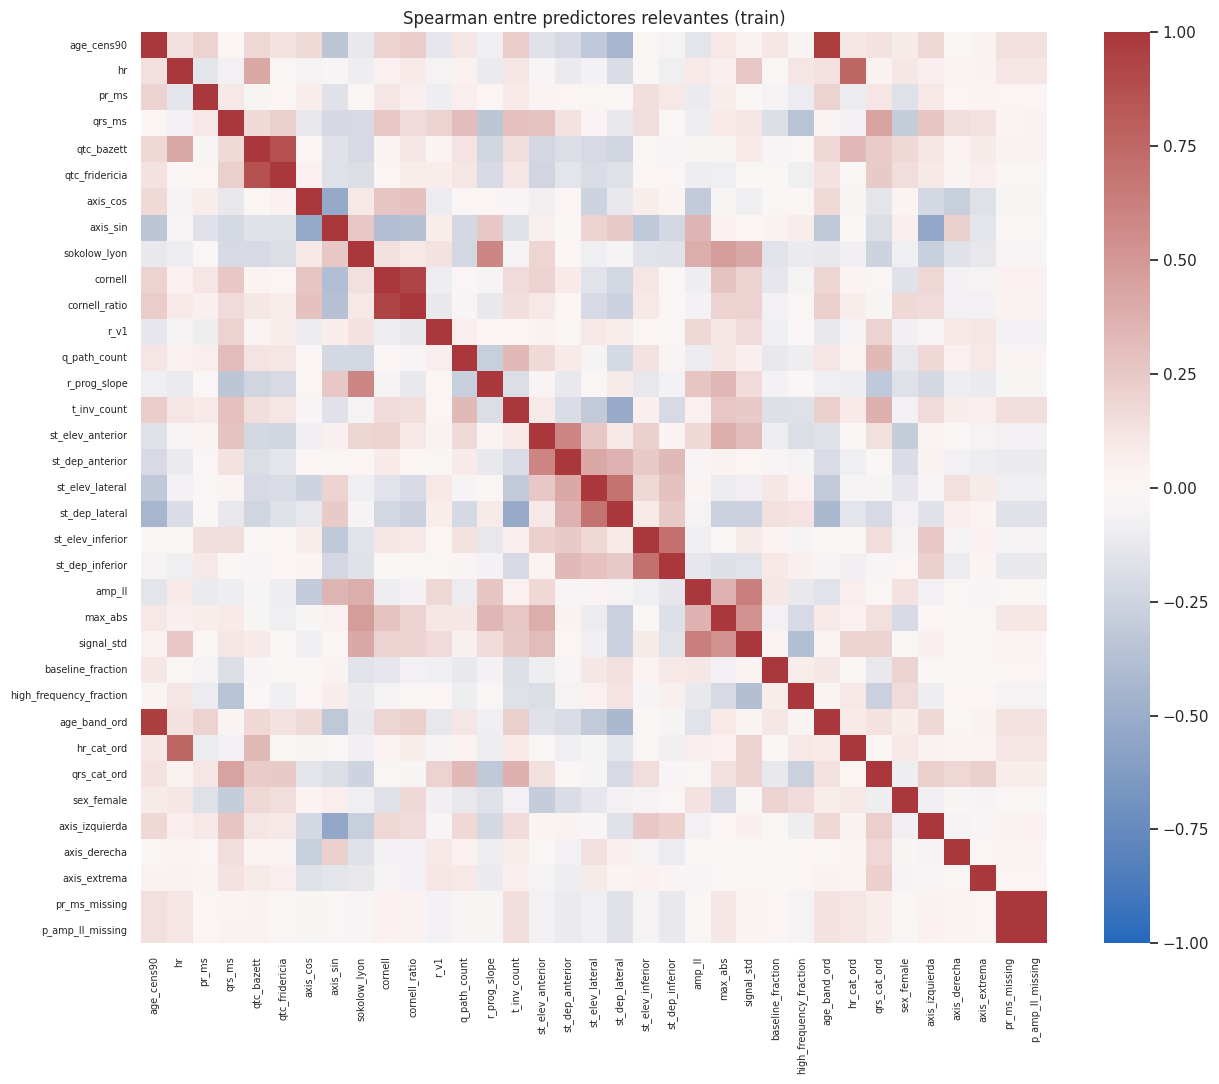

Tras correlación: 32 variables seleccionadas


In [ ]:
corr = X_s.loc[train, after_rel].corr(method="spearman")
pairs = (corr.where(np.triu(np.ones(corr.shape, dtype=bool), k=1)).stack()
         .rename("rho").reset_index().rename(columns={"level_0": "a", "level_1": "b"}))
pairs = pairs.loc[pairs.rho.abs().gt(0.9)].sort_values("rho", key=abs, ascending=False)
kept, drop_corr, decisions = set(after_rel), [], []
for r in pairs.itertuples():
    if r.a in kept and r.b in kept:
        loser = r.a if relevance[r.a] < relevance[r.b] else r.b
        kept.discard(loser); drop_corr.append(loser)
        decisions.append({"par": f"{r.a} ~ {r.b}", "rho": r.rho, "efecto_a": relevance[r.a],
                          "efecto_b": relevance[r.b], "se_elimina": loser})
display(pd.DataFrame(decisions).round(4) if decisions else "Sin pares con |ρ| > 0.9")
selected = [c for c in after_rel if c in kept]

fig, ax = plt.subplots(figsize=(13, 11))
sns.heatmap(corr, cmap="vlag", vmin=-1, vmax=1, center=0, ax=ax, xticklabels=True, yticklabels=True)
ax.tick_params(labelsize=7); ax.set_title("Spearman entre predictores relevantes (train)")
plt.tight_layout(); plt.show()
print(f"Tras correlación: {len(selected)} variables seleccionadas")

**Lectura.** Solo tres pares superaron |ρ| > 0.9, y en cada uno se conservó la variable más relevante:

- `pr_ms_missing` ~ `p_amp_II_missing` (ρ = 0.999): es la misma falla, porque si no hay onda P no hay PR. Se
  conserva un solo indicador (`pr_ms_missing`).
- `age_cens90` ~ `age_band_ord` (ρ = 0.965): la edad continua (0.151) supera a la discretizada (0.143), así que se
  conserva la continua. La censura de 90+ queda resuelta en ambas, sin la mediana de 61.
- `cornell` ~ `cornell_ratio` (ρ = 0.933): el índice crudo (0.068) supera al normalizado por sexo (0.050). La
  hipótesis de que la interacción con el sexo aportaba información no se confirmó para estas superclases. El sexo
  se conserva como variable independiente.

Pares clínicamente relacionados como `qrs_ms` y `qrs_cat_ord`, o `max_abs` y `signal_std`, quedaron por debajo del
umbral y se conservan, porque aportan información parcialmente distinta.

## 5. Extracción de características: PCA y análisis factorial por bloques

El ST en J+60 ms y la amplitud de T se miden en 12 derivaciones (24 variables). Las derivaciones vecinas están
muy correlacionadas porque proyectan el mismo vector eléctrico desde ángulos parecidos; por ejemplo, II, III y
aVF miran la cara inferior. En lugar de elegir derivaciones sueltas, la extracción **combina** cada bloque en
pocas variables nuevas que capturan su variación conjunta.

- **PCA por bloque, no global.** Un PCA sobre todas las variables mezclaría ST, voltajes y edad y daría
  componentes ilegibles. Dentro de un bloque homogéneo, las cargas se interpretan anatómicamente; por ejemplo,
  "desplazamiento global del ST" o "contraste anterior contra inferior". Esto atiende el objetivo de
  facilitar la interpretación.
- **Preparación:** imputación con la mediana, recorte 0.5–99.5 y estandarización, ajustados en train. No se
  aplica Yeo–Johnson: PCA explota relaciones lineales entre derivaciones y una transformación no lineal
  distinta por derivación las distorsionaría. Se estandariza para que las precordiales, de mayor voltaje, no
  dominen solo por su escala.
- **Número de componentes:** el mínimo que explica ≥ 80% de la varianza del bloque.
- **Análisis factorial (rotación varimax)** con el mismo número de factores, como contraste. FA modela
  solo la varianza compartida entre derivaciones y la rotación busca factores con pocas cargas altas; si los
  factores coinciden con territorios anatómicos, eso respalda la interpretación de las componentes.

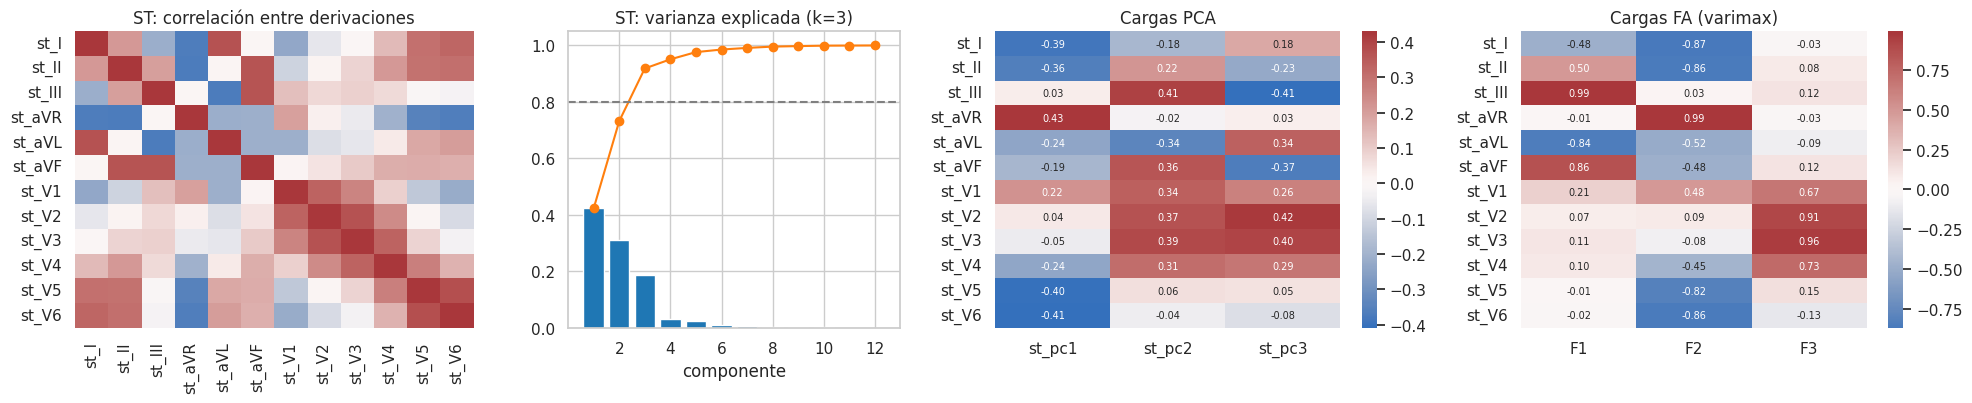

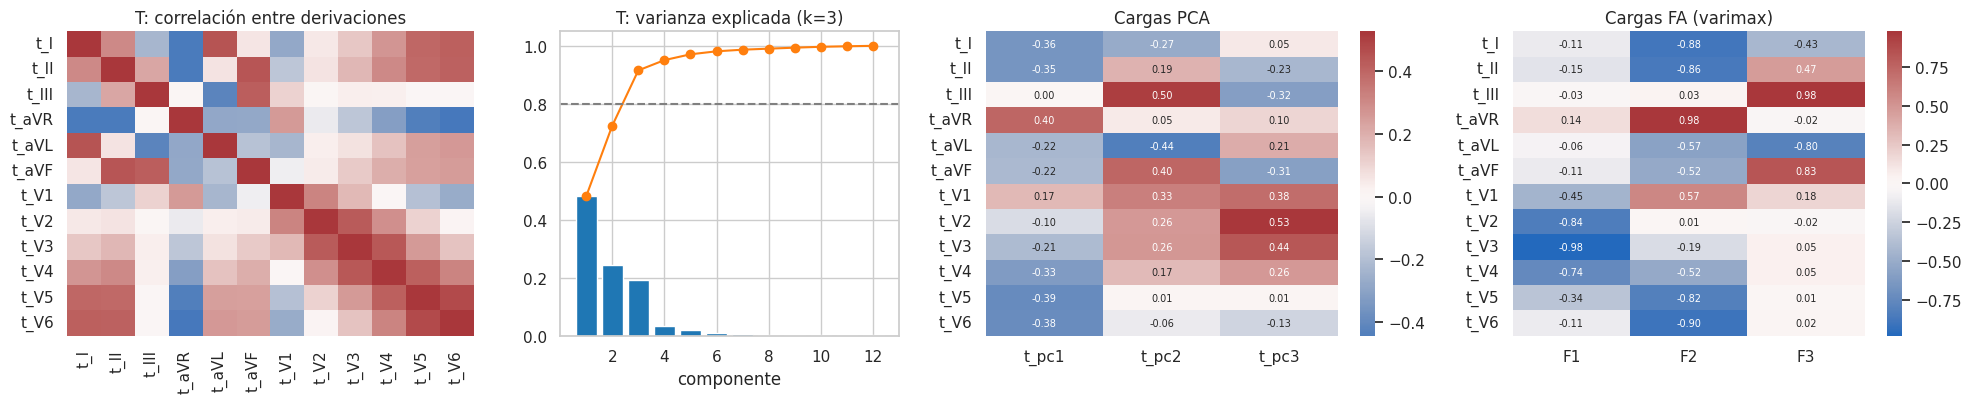

,bloque,variables,componentes,varianza_explicada
0,ST,12,3,0.918
1,T,12,3,0.915


superclase,NORM,MI,STTC,CD,HYP
variable,,,,,
st_pc1,0.1382,0.0126,0.1749,0.0074,0.0864
st_pc2,0.0066,0.0046,0.0138,0.0544,0.0035
st_pc3,0.0081,0.0141,0.0027,0.0055,0.0010
t_pc1,0.2790,0.0968,0.2598,0.0226,0.0544
t_pc2,0.0001,0.0001,0.0013,0.0074,0.0096
t_pc3,0.0019,0.0009,0.0003,0.0001,0.0148


Componentes relevantes (mismo criterio de la sección 4.2): ['st_pc1', 'st_pc2', 'st_pc3', 't_pc1', 't_pc3']


In [ ]:
components, block_info = {}, []
pca_models, fa_models, block_prep = {}, {}, {}
for block, cols in BLOCKS.items():
    B = work[cols].copy()
    med = B.loc[train].median(); B = B.fillna(med)
    blo, bhi = B.loc[train].quantile(.005), B.loc[train].quantile(.995); B = B.clip(blo, bhi, axis=1)
    bsc = StandardScaler().fit(B.loc[train]); Bs = pd.DataFrame(bsc.transform(B), index=B.index, columns=cols)
    block_prep[block] = {"median": med, "lo": blo, "hi": bhi, "scaler": bsc}

    full = PCA().fit(Bs.loc[train])
    cum = np.cumsum(full.explained_variance_ratio_)
    k = int(np.searchsorted(cum, 0.80) + 1)
    pca = PCA(n_components=k).fit(Bs.loc[train])
    fa = FactorAnalysis(n_components=k, rotation="varimax", random_state=SEED).fit(Bs.loc[train])
    pca_models[block], fa_models[block] = pca, fa
    names = [f"{block.lower()}_pc{i + 1}" for i in range(k)]
    components[block] = pd.DataFrame(pca.transform(Bs), index=Bs.index, columns=names)
    block_info.append({"bloque": block, "variables": len(cols), "componentes": k,
                       "varianza_explicada": cum[k - 1]})

    fig, axes = plt.subplots(1, 4, figsize=(20, 4.2), gridspec_kw={"width_ratios": [1.2, 1, 1.3, 1.3]})
    sns.heatmap(Bs.loc[train].corr(), cmap="vlag", vmin=-1, vmax=1, ax=axes[0], cbar=False)
    axes[0].set_title(f"{block}: correlación entre derivaciones")
    axes[1].bar(range(1, 13), full.explained_variance_ratio_, color="tab:blue")
    axes[1].plot(range(1, 13), cum, "o-", color="tab:orange"); axes[1].axhline(0.8, ls="--", color="gray")
    axes[1].set(title=f"{block}: varianza explicada (k={k})", xlabel="componente")
    sns.heatmap(pd.DataFrame(pca.components_.T, index=cols, columns=names), cmap="vlag", center=0, annot=True,
                fmt=".2f", annot_kws={"size": 7}, ax=axes[2]); axes[2].set_title("Cargas PCA")
    sns.heatmap(pd.DataFrame(fa.components_.T, index=cols, columns=[f"F{i + 1}" for i in range(k)]), cmap="vlag",
                center=0, annot=True, fmt=".2f", annot_kws={"size": 7}, ax=axes[3]); axes[3].set_title("Cargas FA (varimax)")
    plt.tight_layout(); plt.show()
display(pd.DataFrame(block_info).round(3))

comp = pd.concat(components.values(), axis=1)
comp_tests = []
for sc in SUPERCLASSES:
    F, pv = f_classif(comp.loc[rel], Y.loc[rel, sc])
    comp_tests += [{"variable": c, "superclase": sc, "p": p_, "efecto": f_ / (f_ + len(rel) - 2)} for c, f_, p_ in zip(comp.columns, F, pv)]
comp_tests = pd.DataFrame(comp_tests)
comp_tests["q_BH"] = stats.false_discovery_control(comp_tests.p.clip(lower=1e-300), method="bh")
comp_tests["relevante"] = comp_tests.q_BH.lt(0.05) & comp_tests.efecto.ge(0.01)
display(comp_tests.pivot(index="variable", columns="superclase", values="efecto")[SUPERCLASSES].round(4))
selected_components = comp_tests.groupby("variable").relevante.any().loc[lambda s: s].index.tolist()
selected_components = [c for c in comp.columns if c in selected_components]
print("Componentes relevantes (mismo criterio de la sección 4.2):", selected_components)

**Lectura.** En ambos bloques, **3 componentes explican más del 91% de la varianza** (ST: 91.8%; T: 91.5%), y a
partir de la cuarta cada componente aporta menos del 5%. Hay dos razones físicas:

1. Las 12 derivaciones solo contienen 8 señales independientes, porque III, aVR, aVL y aVF son combinaciones
   lineales de I y II.
2. La actividad eléctrica del corazón se aproxima como un vector que se mueve en 3 dimensiones (el modelo de
   dipolo en que se basa la vectocardiografía).

PCA recupera esa dimensionalidad desde los datos.

**El análisis factorial con varimax reconstruye los territorios anatómicos sin habérselos indicado.** En el
bloque ST:
- un factor carga en III y aVF, con aVL en sentido opuesto (**cara inferior**);
- otro en I, II, V5 y V6, con aVR opuesto (**cara lateral**);
- otro en V1–V4 (**cara anterior**).

En el bloque T aparece la misma estructura. Esto respalda que las componentes tienen significado clínico y que la
reducción no es una compresión arbitraria.

**Relevancia de las componentes.** `t_pc1` es la variable con mayor efecto de todo el análisis: 0.279 para NORM y
0.260 para STTC. Resume la amplitud y la polaridad global de la T. Se conservan 5 de 6 componentes; `t_pc2` no
superó el criterio. Para el conjunto final se usa PCA porque sus componentes son ortogonales, sin redundancia
entre sí. FA queda como evidencia de interpretación.

## 6. Conjunto final

El conjunto final reúne las variables seleccionadas por filtrado y las componentes relevantes de los bloques.
Para comprobar los objetivos de **reducir almacenamiento y tiempo de entrenamiento**, se compara contra el
conjunto completo de candidatas (todas las construidas, más los 24 valores por derivación sin reducir). El
tiempo se mide con una regresión logística por superclase; de nuevo, sin métricas de desempeño.

In [ ]:
blocks_scaled = pd.concat([pd.DataFrame(block_prep[b]["scaler"].transform(
    work[c].fillna(block_prep[b]["median"]).clip(block_prep[b]["lo"], block_prep[b]["hi"], axis=1)),
    index=work.index, columns=c) for b, c in BLOCKS.items()], axis=1)
X_all = pd.concat([X_s[CONT + ORD + BIN + MISS], blocks_scaled], axis=1)
X_final = pd.concat([X_s[selected], comp[selected_components]], axis=1)

def train_time(X):
    t0 = time.time()
    for sc in SUPERCLASSES:
        LogisticRegression(solver="lbfgs", max_iter=2000).fit(X.loc[train], Y.loc[train, sc])
    return time.time() - t0

summary = pd.DataFrame({
    "variables": [X_all.shape[1], X_final.shape[1]],
    "MB_en_memoria": [X_all.memory_usage(deep=True).sum() / 1e6, X_final.memory_usage(deep=True).sum() / 1e6],
    "segundos_entrenamiento_5_superclases": [train_time(X_all), train_time(X_final)]},
    index=["todas las candidatas", "conjunto final"])
display(summary.round(3))

steps = pd.DataFrame({"paso": ["candidatas (sin bloques)", "umbral de varianza", "relevancia (ANOVA / chi²)",
                               "correlación", "+ componentes de bloques (PCA)"],
                      "variables": [len(CONT + ORD + BIN + MISS), len(after_var), len(after_rel), len(selected),
                                    len(selected) + len(selected_components)]})
display(steps)
final_table = pd.DataFrame({"variable": X_final.columns,
                            "familia": ["Indicador de faltante" if c.endswith("_missing") else
                                        "Bloque PCA" if "_pc" in c else family.get(c, "") for c in X_final.columns],
                            "efecto_max": [relevance.get(c, comp_tests.loc[comp_tests.variable.eq(c), "efecto"].max())
                                           for c in X_final.columns]})
display(final_table.sort_values("efecto_max", ascending=False).round(4))

,variables,MB_en_memoria,segundos_entrenamiento_5_superclases
todas las candidatas,92,16.44,3.949
conjunto final,37,7.03,3.378


,paso,variables
0,candidatas (sin bloques),68
1,umbral de varianza,38
2,relevancia (ANOVA / chi²),35
3,correlación,32
4,+ componentes de bloques (PCA),37


,variable,familia,efecto_max
35,t_pc1,Bloque PCA,0.2790
26,qrs_cat_ord,Intervalos,0.2227
28,axis_izquierda,Eje,0.2078
11,q_path_count,Onda Q / R,0.2006
17,st_dep_lateral,ST,0.1976
3,qrs_ms,Intervalos,0.1943
13,t_inv_count,Onda T,0.1922
32,st_pc1,Bloque PCA,0.1749
0,age_cens90,Demografía,0.1505
7,axis_sin,Eje,0.1284


In [ ]:
for name in ["train", "validation", "test"]:
    mask = split.eq(name)
    X_final.loc[mask].to_parquet(OUT / f"X_{name}.parquet")
    Y.loc[mask].to_parquet(OUT / f"Y_{name}.parquet")
meta.loc[supervised, ["patient_id", "filename_hr", "split"]].to_csv(OUT / "indice_conjunto_final.csv")
selection_log = pd.concat([
    pd.DataFrame({"variable": drop_var, "paso": "umbral de varianza"}),
    pd.DataFrame({"variable": drop_rel, "paso": "relevancia"}),
    pd.DataFrame({"variable": drop_corr, "paso": "correlación"})])
selection_log.to_csv(OUT / "variables_eliminadas.csv", index=False)
final_table.to_csv(OUT / "variables_finales.csv", index=False)

manifest = {
    "dataset": "PTB-XL 1.0.3", "mode": MODE, "started_at_utc": RUN_STARTED,
    "completed_at_utc": datetime.now(timezone.utc).isoformat(), "python": platform.python_version(),
    "versions": versions, "feature_module_sha256_12": module_hash,
    "n_supervised": int(len(supervised)), "splits": split.value_counts().to_dict(),
    "train_folds": list(range(1, 9)), "validation_fold": 9, "test_fold": 10,
    "imputation_medians_train": medians.round(6).to_dict(), "imputation_modes_train": modes.to_dict(),
    "winsor_limits_train": {"p0.5": lo.round(6).to_dict(), "p99.5": hi.round(6).to_dict()},
    "yeojohnson_lambdas_train": dict(zip(to_transform, map(float, yj.lambdas_))),
    "yeojohnson_prescale_train": {"mean": dict(zip(to_transform, map(float, pre_yj.mean_))),
                                  "scale": dict(zip(to_transform, map(float, pre_yj.scale_)))},
    "scaler_mean_train": dict(zip(SCALE, map(float, scaler.mean_))),
    "scaler_scale_train": dict(zip(SCALE, map(float, scaler.scale_))),
    "selection": {"variance_dropped": drop_var, "relevance_dropped": drop_rel, "correlation_dropped": drop_corr,
                  "criteria": "q_BH<0.05 y efecto>=0.01 en ≥1 superclase; |Spearman|>0.9"},
    "pca": {b: {"k": int(m.n_components_), "explained": float(m.explained_variance_ratio_.sum())} for b, m in pca_models.items()},
    "final_features": X_final.columns.tolist()}
(OUT / "manifest_avance2.json").write_text(json.dumps(manifest, ensure_ascii=False, indent=2, default=str), encoding="utf-8")
forbidden = {"report", "scp_codes", "heart_axis", "patient_id", "infarction_stadium1", *SUPERCLASSES}
assert forbidden.isdisjoint(X_final.columns), "Fuga de etiqueta en predictores"
assert X_final.notna().all().all() and np.isfinite(X_final.to_numpy(dtype=float)).all()
print("Archivos guardados en", OUT)

Archivos guardados en /content/drive/MyDrive/ECG project/avance2_ingenieria_caracteristicas


**Lectura.** El conjunto final tiene **37 variables frente a 92 candidatas** (−60%): 32 seleccionadas por filtrado
y 5 componentes. La memoria baja de 16.4 a 7.0 MB (−57%) y el entrenamiento de referencia de 3.95 a 3.38 s (−14%).

La ganancia en tiempo es moderada porque, una vez escaladas, las variables ya convergen rápido: la reducción
principal es de **complejidad y redundancia**. Además, cada variable final tiene una interpretación clínica
documentada en el diccionario de características.

## 7. Conclusiones de la fase de Preparación de datos (CRISP-ML)

En CRISP-ML(Q), la Preparación de datos convierte los datos crudos en un conjunto apto para modelar mediante
**selección, limpieza, construcción y estandarización**, con aseguramiento de calidad en cada paso. Esta
fase abarcó el Avance 1 (EDA y limpieza) y este Avance 2 (ingeniería de características). Las conclusiones se
generan con los resultados de la ejecución y se organizan por tarea de la fase.

In [ ]:
n_tr = int(train.sum())
top = relevance.loc[selected].sort_values(ascending=False).head(5)
validated = meta.loc[supervised].groupby("split").validated_by_human.mean()
saga = convergence.query("solver == 'saga'").groupby("variables").agg(iter=("iteraciones", "median"), ok=("convergio", "mean"))
conclusions = [
    ("Selección de datos",
     f"La vista supervisada contiene {len(supervised):,} ECG ({n_tr:,} de entrenamiento) con las cinco superclases como objetivo "
     f"multietiqueta. Se conservaron los folds oficiales sin pacientes compartidos entre particiones y se excluyeron, como en el "
     f"Avance 1, los ECG sin superclase diagnóstica o con canal constante."),
    ("Limpieza",
     f"La delineación se completó en {sig.loc[supervised, 'status'].eq('ok').mean():.1%} de los ECG. Los valores fisiológicamente "
     f"imposibles se trataron como fallas de medición, no como hallazgos. Las continuas se imputaron con medianas de entrenamiento "
     f"con indicador de faltante, y los extremos se recortaron a los percentiles 0.5–99.5 de entrenamiento sin eliminar registros."),
    ("Construcción",
     f"Se construyeron {len(CONT)} características continuas (ritmo, intervalos, eje, voltaje, ST, T, Q y R con fundamento clínico, "
     f"más edad y covariables de calidad) "
     f"más 24 medidas por derivación, además de interacciones (Cornell/umbral por sexo), codificación circular del eje y "
     f"discretización con umbrales clínicos. Las de mayor efecto fueron: "
     + ", ".join(f"{c} ({v:.3f})" for c, v in top.items()) + "."),
    ("Estandarización",
     f"{len(to_transform)} variables con |asimetría| > 1 se transformaron con Yeo–Johnson y todas las continuas y ordinales se "
     f"estandarizaron. Con saga, la mediana de iteraciones pasó de {saga.loc['sin escalar', 'iter']:.0f} sin escalar a "
     f"{saga.loc['escaladas', 'iter']:.0f} con escalamiento (convergencia en {saga.loc['sin escalar', 'ok']:.0%} contra "
     f"{saga.loc['escaladas', 'ok']:.0%} de las superclases)."),
    ("Selección y extracción",
     f"De {len(CONT + ORD + BIN + MISS)} candidatas, el umbral de varianza eliminó {len(drop_var)}, la relevancia {len(drop_rel)} "
     f"y la correlación {len(drop_corr)}. Los bloques de ST y T (24 variables) se redujeron a {comp.shape[1]} componentes, de las "
     f"que {len(selected_components)} resultaron relevantes. El conjunto final tiene {X_final.shape[1]} variables frente a "
     f"{X_all.shape[1]} candidatas, y el entrenamiento de referencia pasó de {summary.iloc[0, 2]:.2f} s a {summary.iloc[1, 2]:.2f} s."),
    ("Aseguramiento de calidad",
     "Todos los parámetros se ajustaron solo con entrenamiento y se guardaron en un manifiesto. Las pruebas de relevancia usaron un "
     "ECG por paciente y corrección FDR. Ningún predictor deriva del reporte, de los códigos SCP ni de anotaciones humanas del eje. "
     "La caché de características está ligada al código que la generó."),
    ("Entrega a la fase de Modelado",
     f"Se entregan X/Y por partición en Parquet, con {X_final.shape[1]} variables escaladas sin faltantes, el diccionario de "
     f"características y el registro de decisiones. Riesgos que hereda el modelado: la delineación es un descriptor operativo sin "
     f"validación clínica independiente; PTB-XL es un sustituto del dataset del proyecto, por lo que el procedimiento es "
     f"transferible pero los parámetros ajustados no; y la validación y la prueba tienen una calidad de etiqueta distinta a la de "
     f"entrenamiento ({validated.get('validation', np.nan):.0%} y {validated.get('test', np.nan):.0%} validadas por humano, contra "
     f"{validated.get('train', np.nan):.0%})."),
]
for topic, text in conclusions:
    display(Markdown(f"**{topic}.** {text}"))
pd.DataFrame(conclusions, columns=["tarea_crisp_ml", "conclusion"]).to_csv(OUT / "conclusiones.csv", index=False)

**Selección de datos.** La vista supervisada contiene 21,387 ECG (17,083 de entrenamiento) con las cinco superclases como objetivo multietiqueta. Se conservaron los folds oficiales sin pacientes compartidos entre particiones y se excluyeron, como en el Avance 1, los ECG sin superclase diagnóstica o con canal constante.

**Limpieza.** La delineación se completó en 99.9% de los ECG. Los valores fisiológicamente imposibles se trataron como fallas de medición, no como hallazgos. Las continuas se imputaron con medianas de entrenamiento con indicador de faltante, y los extremos se recortaron a los percentiles 0.5–99.5 de entrenamiento sin eliminar registros.

**Construcción.** Se construyeron 29 características continuas (ritmo, intervalos, eje, voltaje, ST, T, Q y R con fundamento clínico, más edad y covariables de calidad) más 24 medidas por derivación, además de interacciones (Cornell/umbral por sexo), codificación circular del eje y discretización con umbrales clínicos. Las de mayor efecto fueron: qrs_cat_ord (0.223), axis_izquierda (0.208), q_path_count (0.201), st_dep_lateral (0.198), qrs_ms (0.194).

**Estandarización.** 20 variables con |asimetría| > 1 se transformaron con Yeo–Johnson y todas las continuas y ordinales se estandarizaron. Con saga, la mediana de iteraciones pasó de 1000 sin escalar a 262 con escalamiento (convergencia en 0% contra 100% de las superclases).

**Selección y extracción.** De 68 candidatas, el umbral de varianza eliminó 30, la relevancia 3 y la correlación 3. Los bloques de ST y T (24 variables) se redujeron a 6 componentes, de las que 5 resultaron relevantes. El conjunto final tiene 37 variables frente a 92 candidatas, y el entrenamiento de referencia pasó de 3.95 s a 3.38 s.

**Aseguramiento de calidad.** Todos los parámetros se ajustaron solo con entrenamiento y se guardaron en un manifiesto. Las pruebas de relevancia usaron un ECG por paciente y corrección FDR. Ningún predictor deriva del reporte, de los códigos SCP ni de anotaciones humanas del eje. La caché de características está ligada al código que la generó.

**Entrega a la fase de Modelado.** Se entregan X/Y por partición en Parquet, con 37 variables escaladas sin faltantes, el diccionario de características y el registro de decisiones. Riesgos que hereda el modelado: la delineación es un descriptor operativo sin validación clínica independiente; PTB-XL es un sustituto del dataset del proyecto, por lo que el procedimiento es transferible pero los parámetros ajustados no; y la validación y la prueba tienen una calidad de etiqueta distinta a la de entrenamiento (100% y 100% validadas por humano, contra 68%).

**Lectura final.** La fase de Preparación de datos deja un conjunto apto para modelar y cumple los dos objetivos
del avance:

- **2.3, mejorar el rendimiento:** las características construidas superan en asociación a las disponibles en el
  EDA y cubren las cinco superclases con variables propias.
- **2.4, mitigar el sesgo y acelerar la convergencia:** se redujo la asimetría y se demostró la mejora en la
  convergencia con evidencia medida.

Hay tres riesgos que debe considerar la fase de Modelado:
1. **Calidad de etiqueta distinta entre particiones:** validación y prueba están validadas al 100% por humano,
   contra 68% en entrenamiento. Las métricas de prueba podrían ser más optimistas o más estrictas que el ruido de
   etiqueta que el modelo vio al entrenar.
2. **Delineación sin validación clínica externa:** se calibró con un solo registro real y se verificó
   visualmente, pero no se comparó contra mediciones de referencia.
3. **Transferencia al dataset del proyecto:** el procedimiento es reproducible y se puede transferir, pero los
   parámetros (medianas, λ, cargas de PCA) deben reajustarse con el entrenamiento de ese dataset.